# Dog Breed Arena
## Compétition de classification d'images par Transfer Learning

**Durée :** 3 heures  
**Équipe :** binôme (2 étudiants)  
**Environnement :** Google Colab avec GPU  
**Métrique officielle :** Multi-class Log Loss (plus faible = meilleur)

---

Ce notebook ne contient **aucun code**. Il vous donne la mission, les contraintes et les attentes. L'organisation du travail, l'ordre des étapes, le choix des bibliothèques (PyTorch ou TensorFlow/Keras) et la structure du notebook vous appartiennent entièrement.

Lisez attentivement la fiche de règlement de la compétition avant de commencer : elle contient la procédure de téléchargement des données, les règles, le planning et le barème.

## Identification du binôme

- **Membre 1 :**
- **Membre 2 :**
- **Nom d'équipe :**
- **Framework choisi :** PyTorch + torchvision (poids ImageNet-1k officiels)
- **Modèle étudié et défendu :** AlexNet

## 1. La mission

Vous devez construire un système qui, pour chaque photo de chien, prédit la **probabilité d'appartenance à chacune des 120 races** possibles.

C'est un problème de **classification fine** (*fine-grained classification*) : les classes sont visuellement très proches, et le nombre d'images par race est limité (environ 85 en moyenne). Entraîner un CNN de zéro dans ces conditions et en 3 heures n'est pas réaliste. La solution passe par le **Transfer Learning** à partir de modèles pré-entraînés sur ImageNet.

L'objectif est double :

1. **Comparer scientifiquement** plusieurs grandes architectures CNN sur ce problème.
2. **Obtenir le meilleur score possible** sur le classement officiel.

## 2. Les données

Une fois téléchargées dans Colab (voir la fiche de règlement), vous disposez de :

| Élément | Description |
|---|---|
| `train/` | 10 222 images d'entraînement, nommées `id.jpg` |
| `labels.csv` | Correspondance entre `id` et `breed` pour l'entraînement |
| `test/` | 10 357 images à prédire, sans étiquette |
| `sample_submission.csv` | Format exact de la soumission : `id` + 120 colonnes de probabilités |

Avant de modéliser, prenez le temps de **comprendre ces données** : répartition des classes, tailles et formats des images, qualité, présence de plusieurs chiens ou d'éléments perturbateurs. Les observations que vous ferez ici doivent influencer vos choix ultérieurs.

## 3. Ce qui est attendu dans votre notebook

Les éléments ci-dessous doivent tous apparaître dans votre travail. **L'ordre et la manière de les réaliser sont libres.**

### A. Un protocole d'évaluation fiable
- Un jeu de validation construit à partir de `train/`, représentatif des 120 races, et **identique pour tous les modèles comparés**.
- Un protocole reproductible (pensez au contrôle de l'aléatoire).

### B. Un benchmark d'au moins 5 architectures pré-entraînées
- **Imposées :** AlexNet, VGG16, ResNet50, MobileNetV2.
- **Au moins une au choix :** EfficientNet, DenseNet, InceptionV3, Xception, ConvNeXt, RegNet ou autre. Justifiez votre choix.
- Chaque modèle doit être utilisé avec les prétraitements qui lui correspondent (résolution d'entrée, normalisation du pré-entraînement).

### C. Un tableau comparatif et au moins un graphique
Pour chaque modèle, au minimum :
- Log Loss de validation
- Accuracy de validation
- Nombre de paramètres
- Stratégie utilisée (extraction de features, fine-tuning partiel ou complet)
- Temps d'entraînement
- Temps d'inférence moyen par image

### D. Une démarche d'optimisation
À partir des résultats du benchmark, améliorez votre meilleure approche. Chaque amélioration tentée doit être **mesurée** sur la validation, qu'elle fonctionne ou non. Une tentative ratée mais bien analysée a de la valeur.

### E. Une analyse des erreurs
Identifiez les races que votre modèle final confond le plus souvent, visualisez quelques exemples d'erreurs et proposez une explication.

### F. La soumission officielle
- Un fichier `submission.csv` conforme à `sample_submission.csv`.
- La soumission sur la plateforme et une **capture d'écran du score** insérée dans le notebook.

### G. Une conclusion argumentée
Quel modèle recommanderiez-vous pour un déploiement sur serveur ? Et pour une application mobile ? Appuyez-vous sur vos chiffres.

## 4. Pistes de réflexion

Ces questions ne sont pas des étapes imposées. Elles sont là pour vous aider à prendre de bonnes décisions.

- Avec 3 heures et un seul GPU, combien de modèles pouvez-vous réellement fine-tuner complètement ? Existe-t-il une stratégie plus rapide pour comparer équitablement plusieurs architectures ?
- Si vous calculez une fois pour toutes la représentation des images par un réseau gelé, que pouvez-vous ensuite entraîner très rapidement dessus ?
- La métrique est la Log Loss, pas l'Accuracy. Qu'est-ce qui pénalise le plus un modèle avec cette métrique ? Comment éviter des probabilités trop extrêmes ?
- L'augmentation de données est-elle utile si le réseau est gelé et les features pré-calculées ?
- Plusieurs modèles différents font-ils les mêmes erreurs ? Que peut-on en tirer ?
- Prédire une image et sa version retournée horizontalement apporte-t-il quelque chose ?
- Que se passe-t-il si votre session Colab se déconnecte à la minute 130 ? Que devez-vous avoir sauvegardé ?
- Une fois le meilleur protocole trouvé, est-il pertinent de réentraîner sur la totalité de `train/` avant la soumission ?

## 5. Questions auxquelles vous devrez répondre

Répondez à ces questions dans votre notebook, avec vos propres mots et en vous appuyant sur vos résultats. L'enseignant pourra interroger n'importe quel membre du binôme.

1. Pourquoi un modèle pré-entraîné sur ImageNet est-il particulièrement efficace sur ce problème ?
2. Quelle est la différence entre extraction de features et fine-tuning ? Laquelle avez-vous choisie et pourquoi ?
3. Pourquoi VGG16 possède-t-il beaucoup plus de paramètres que ResNet50 alors qu'il est moins profond ?
4. Que permettent les connexions résiduelles de ResNet ? Et les convolutions séparables de MobileNetV2 ?
5. Le classement de vos modèles est-il le même selon l'Accuracy et selon la Log Loss ? Expliquez.
6. Comment avez-vous détecté et limité l'overfitting ?
7. Quelle amélioration a eu le plus d'impact sur votre score, et pourquoi selon vous ?

## 6. Liste de vérification avant de rendre

- [ ] Le notebook s'exécute de haut en bas sans erreur, et les sorties sont visibles.
- [ ] Les 4 modèles imposés et au moins 1 modèle libre ont été évalués avec le même jeu de validation.
- [ ] Le tableau comparatif contient toutes les colonnes demandées.
- [ ] Au moins un graphique compare les modèles.
- [ ] Chaque optimisation tentée est mesurée et commentée.
- [ ] Les erreurs du modèle final sont analysées.
- [ ] `submission.csv` a exactement les mêmes colonnes, dans le même ordre, que `sample_submission.csv`.
- [ ] Chaque ligne contient 120 probabilités dont la somme vaut 1.
- [ ] La capture du score officiel est insérée.
- [ ] Les réponses aux questions et la conclusion sont rédigées.
- [ ] Aucune donnée externe, aucun code copié depuis des solutions publiques.

---

## Votre travail commence ici

Ajoutez autant de cellules de code et de texte que nécessaire, et organisez-les comme vous le souhaitez. Commentez vos choix au fur et à mesure : un résultat sans explication ne rapporte que peu de points.

Bonne compétition.

# 0. Notre démarche : étude approfondie d'AlexNet

Conformément à la consigne de l'enseignant, ce travail défend **un seul modèle : AlexNet** (Krizhevsky, Sutskever & Hinton, 2012).
La comparaison scientifique ne porte donc pas sur plusieurs architectures, mais sur **plusieurs façons d'exploiter AlexNet par transfer learning**, toutes évaluées avec le même protocole.

| Code | Stratégie | Ce qui est appris |
|---|---|---|
| S1 | extraction : sortie de `pool5` + pooling global (256 dim.) | régression logistique |
| S2 | extraction : sortie de `pool5` aplatie (9 216 dim.) | régression logistique |
| S3 | extraction : couche `fc6` (4 096 dim.) | régression logistique |
| S4 | extraction : couche `fc7` (4 096 dim.) | régression logistique |
| S5 | **fine-tuning partiel** : convolutions gelées, `fc6`, `fc7` et nouvelle `fc8` réentraînées | 54,6 M paramètres |
| S6 | **fine-tuning complet** : tout le réseau réentraîné | 57,5 M paramètres |

Ensuite, une **démarche d'optimisation** mesurée étape par étape : augmentation par miroir, régularisation, **résolution d'entrée** (le premier filtre 11×11 de pas 4 limite-t-il AlexNet ?), TTA miroir et **TTA 10 crops** (la méthode d'évaluation du papier original), calibration par température.

Enfin, des **améliorations avancées** (section 11 bis), choisies à partir du diagnostic de nos propres résultats :
**entraînement multi-vues** (12 vues de chaque image pour lutter contre la mémorisation), **fine-tuning régularisé** (mixup, recadrages forts) et **ensemble pondéré** de tous les modèles.

**Pourquoi c'est faisable en 3 h** : AlexNet est le réseau le plus léger à calculer (~1 ms par image sur T4). Les extractions prennent une minute, un fine-tuning complet environ 5 minutes.

**Plan des 3 soumissions**

| # | Moment | Contenu |
|---|---|---|
| 1 | ~ min 70 | meilleure stratégie du benchmark, telle quelle (sécurité) |
| 2 | ~ min 140 | modèle final optimisé, entraîné sur 80 % du train |
| 3 | ~ min 155 | même recette réentraînée sur 100 % de `train/` |

**Résistance aux déconnexions** : le split, les mesures, les résultats des fine-tunings (logits de validation et de test) et les soumissions sont écrits sur Google Drive. Chaque cellule coûteuse recharge son résultat s'il existe. Après une déconnexion, **relancez tout de haut en bas** : seuls le cache d'images (~5 min) et les features (~3 min) sont recalculés.

**Planning**

| Minutes | Sections |
|---|---|
| 0–15 | 1 à 2 : environnement, téléchargement |
| 15–35 | 3 à 5 : exploration, protocole, cache d'images |
| 35–75 | 6 à 10 : AlexNet, extraction, benchmark des stratégies, **soumission 1** |
| 75–135 | 11 : optimisation (chaque essai mesuré) |
| 135–160 | 12 à 13 : analyse d'erreurs, **soumissions 2 et 3** |
| 160–180 | 14 à 17 : capture du score, réponses, conclusion |

# 1. Environnement et reproductibilité

In [5]:
import os, sys, time, json, math, random, copy, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
from IPython.display import display

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision import models
from scipy.special import softmax, log_softmax
from scipy.optimize import minimize_scalar
from sklearn.model_selection import StratifiedShuffleSplit, StratifiedKFold

warnings.filterwarnings("ignore")
pd.set_option("display.precision", 4)
pd.set_option("display.max_colwidth", 80)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"PyTorch {torch.__version__} | torchvision {torchvision.__version__} | device = {DEVICE}")
if DEVICE == "cuda":
    print("GPU :", torch.cuda.get_device_name(0))
else:
    print("ATTENTION : aucun GPU. Exécution → Modifier le type d'exécution → GPU (T4)")

# --- Contrôle de l'aléatoire ---
SEED = 42
def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything()
# cudnn.benchmark accélère les convolutions ; les écarts numériques (~1e-3) sont sans effet sur les métriques.
torch.backends.cudnn.benchmark = True

PyTorch 2.11.0+cu130 | torchvision 0.26.0+cu130 | device = cuda
GPU : Tesla T4


In [6]:
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    WORK_DIR = "/content/drive/MyDrive/dog_breed_arena_alexnet"   # sauvegardes persistantes
    LOCAL_DIR = "/content/local"                                   # cache rapide (perdu si déconnexion)
else:
    WORK_DIR = os.path.abspath("dog_breed_arena_alexnet")
    LOCAL_DIR = os.path.abspath("local")

FEAT_DIR = os.path.join(LOCAL_DIR, "alexnet_features")   # features : recalculées en ~3 min si perdues
FT_DIR   = os.path.join(WORK_DIR, "finetuning")          # résultats des fine-tunings (coûteux) → Drive
FIG_DIR  = os.path.join(WORK_DIR, "figures")
SUB_DIR  = os.path.join(WORK_DIR, "submissions")
for d in (WORK_DIR, LOCAL_DIR, FEAT_DIR, FT_DIR, FIG_DIR, SUB_DIR):
    os.makedirs(d, exist_ok=True)
print("Sauvegardes dans :", WORK_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Sauvegardes dans : /content/drive/MyDrive/dog_breed_arena_alexnet


# 2. Téléchargement des données (procédure de la fiche de règlement)

In [7]:
# ÉTAPE 1 — exécuter cette cellule SEULE, coller le token Kaggle dans le champ « API Token », cliquer sur Login.
# (Dans Colab, login() n'attend pas la saisie : le téléchargement doit donc être dans la cellule suivante.)
# Token : kaggle.com → photo de profil → Settings → API → créer un nouveau token.
import kagglehub
kagglehub.login()

In [8]:
# ÉTAPE 2 — à exécuter APRÈS la connexion. En cas d'erreur 403 : accepter le règlement sur la page de la compétition.
path = kagglehub.competition_download("dog-breed-identification")
print("Path to competition files:", path)

DATA_DIR = next((root for root, _, files in os.walk(path) if "labels.csv" in files), None)
assert DATA_DIR is not None, "labels.csv introuvable"
print("DATA_DIR =", DATA_DIR)
print(sorted(os.listdir(DATA_DIR)))

100%|██████████| 691M/691M [00:42<00:00, 17.0MB/s]

Extracting files...


Path to competition files: /root/.cache/kagglehub/competitions/dog-breed-identification
DATA_DIR = /root/.cache/kagglehub/competitions/dog-breed-identification
['labels.csv', 'sample_submission.csv', 'test', 'train']


In [9]:
labels = pd.read_csv(os.path.join(DATA_DIR, "labels.csv"))
sample = pd.read_csv(os.path.join(DATA_DIR, "sample_submission.csv"))

BREEDS = list(sample.columns[1:])                  # ordre officiel des 120 colonnes de soumission
BREED2IDX = {b: i for i, b in enumerate(BREEDS)}
N_CLASSES = len(BREEDS)
y_all = labels["breed"].map(BREED2IDX).values.astype(int)

train_paths = [os.path.join(DATA_DIR, "train", f"{i}.jpg") for i in labels["id"]]
test_ids = sample["id"].tolist()
test_paths = [os.path.join(DATA_DIR, "test", f"{i}.jpg") for i in test_ids]
N_TRAIN, N_TEST = len(train_paths), len(test_paths)

assert N_CLASSES == 120, N_CLASSES
assert set(labels["breed"]) == set(BREEDS), "races de labels.csv ≠ colonnes de sample_submission"
assert all(os.path.exists(p) for p in train_paths) and all(os.path.exists(p) for p in test_paths)
print(f"{N_TRAIN} images train | {N_TEST} images test | {N_CLASSES} races — tous les fichiers sont présents")
labels.head()

10222 images train | 10357 images test | 120 races — tous les fichiers sont présents


,id,breed
0,000bec180eb18c7604dcecc8fe0dba07,boston_bull
1,001513dfcb2ffafc82cccf4d8bbaba97,dingo
2,001cdf01b096e06d78e9e5112d419397,pekinese
3,00214f311d5d2247d5dfe4fe24b2303d,bluetick
4,0021f9ceb3235effd7fcde7f7538ed62,golden_retriever


# 3. Exploration des données

Images par race : min = 66 (eskimo_dog), max = 126 (scottish_deerhound), moyenne = 85.2, médiane = 82
Ratio de déséquilibre max / min = 1.91


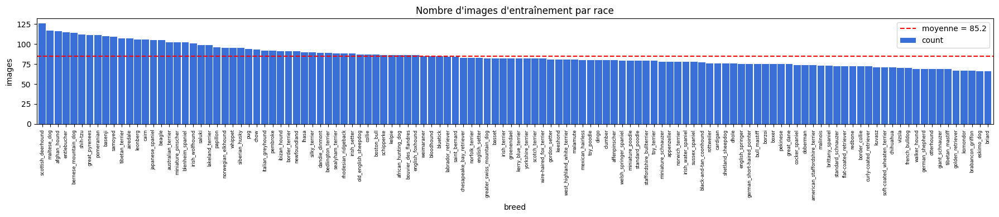

In [10]:
counts = labels["breed"].value_counts()
print(f"Images par race : min = {counts.min()} ({counts.idxmin()}), max = {counts.max()} ({counts.idxmax()}), "
      f"moyenne = {counts.mean():.1f}, médiane = {counts.median():.0f}")
print(f"Ratio de déséquilibre max / min = {counts.max() / counts.min():.2f}")

fig, ax = plt.subplots(figsize=(18, 4))
counts.plot.bar(ax=ax, width=0.9, color="#3b6fd8")
ax.axhline(counts.mean(), color="red", ls="--", label=f"moyenne = {counts.mean():.1f}")
ax.set_title("Nombre d'images d'entraînement par race")
ax.set_ylabel("images")
ax.tick_params(axis="x", labelsize=6)
ax.legend()
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "eda_classes.png"), dpi=120); plt.show()

en-têtes train:   0%|          | 0/10222 [00:00<?, ?it/s]

en-têtes test (échantillon):   0%|          | 0/2000 [00:00<?, ?it/s]

--- train ---
  largeur médiane 500 px, hauteur médiane 375 px, plus petite 97x102, plus grande 3264x2562
  côté court < 224 px : 7.7 %  |  modes : {'RGB': 10222}  |  formats : {'JPEG': 10222}
--- test (échantillon de 2000) ---
  largeur médiane 500 px, hauteur médiane 375 px, plus petite 108x120, plus grande 2400x1926
  côté court < 224 px : 7.4 %  |  modes : {'RGB': 2000}  |  formats : {'JPEG': 2000}


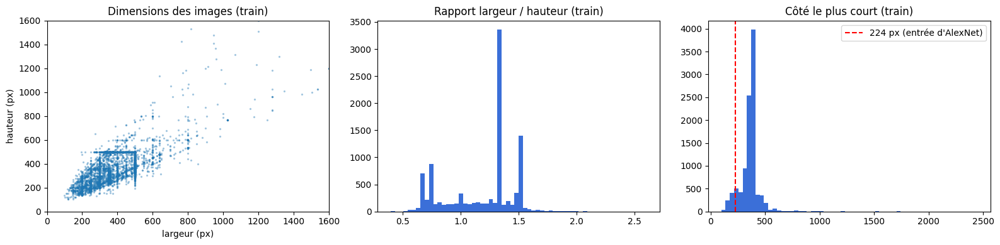

In [11]:
def read_meta(p):
    with Image.open(p) as im:          # lit seulement l'en-tête : rapide
        return im.size[0], im.size[1], im.mode, im.format

meta_train = pd.DataFrame([read_meta(p) for p in tqdm(train_paths, desc="en-têtes train")],
                          columns=["w", "h", "mode", "format"])
rng = np.random.RandomState(SEED)
idx_t = rng.choice(N_TEST, size=min(2000, N_TEST), replace=False)
meta_test = pd.DataFrame([read_meta(test_paths[i]) for i in tqdm(idx_t, desc="en-têtes test (échantillon)")],
                         columns=["w", "h", "mode", "format"])

for name, m in [("train", meta_train), ("test (échantillon de 2000)", meta_test)]:
    short = m[["w", "h"]].min(axis=1)
    print(f"--- {name} ---")
    print(f"  largeur médiane {m.w.median():.0f} px, hauteur médiane {m.h.median():.0f} px, "
          f"plus petite {m.w.min()}x{m.h.min()}, plus grande {m.w.max()}x{m.h.max()}")
    print(f"  côté court < 224 px : {(short < 224).mean() * 100:.1f} %  |  modes : {m['mode'].value_counts().to_dict()}"
          f"  |  formats : {m['format'].value_counts().to_dict()}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].scatter(meta_train.w, meta_train.h, s=2, alpha=0.3)
axes[0].set(xlabel="largeur (px)", ylabel="hauteur (px)", title="Dimensions des images (train)", xlim=(0, 1600), ylim=(0, 1600))
axes[1].hist(meta_train.w / meta_train.h, bins=60, color="#3b6fd8")
axes[1].set_title("Rapport largeur / hauteur (train)")
axes[2].hist(meta_train[["w", "h"]].min(axis=1), bins=60, color="#3b6fd8")
axes[2].axvline(224, color="red", ls="--", label="224 px (entrée d'AlexNet)"); axes[2].legend()
axes[2].set_title("Côté le plus court (train)")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "eda_tailles.png"), dpi=120); plt.show()

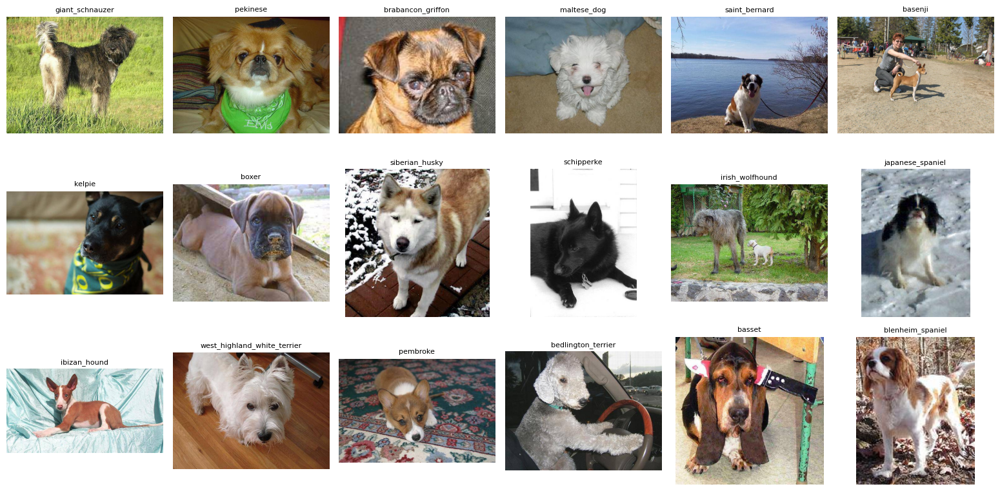

In [12]:
def show_images(images, titles, ncols=6, size=2.6):
    """images : chemins de fichiers ou tableaux numpy"""
    nrows = math.ceil(len(images) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * size, nrows * size))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes:
        ax.axis("off")
    for ax, im, t in zip(axes, images, titles):
        ax.imshow(Image.open(im).convert("RGB") if isinstance(im, str) else im)
        ax.set_title(t, fontsize=8)
    plt.tight_layout(); plt.show()

idx = rng.choice(N_TRAIN, 18, replace=False)
show_images([train_paths[i] for i in idx], [labels.breed[i] for i in idx])

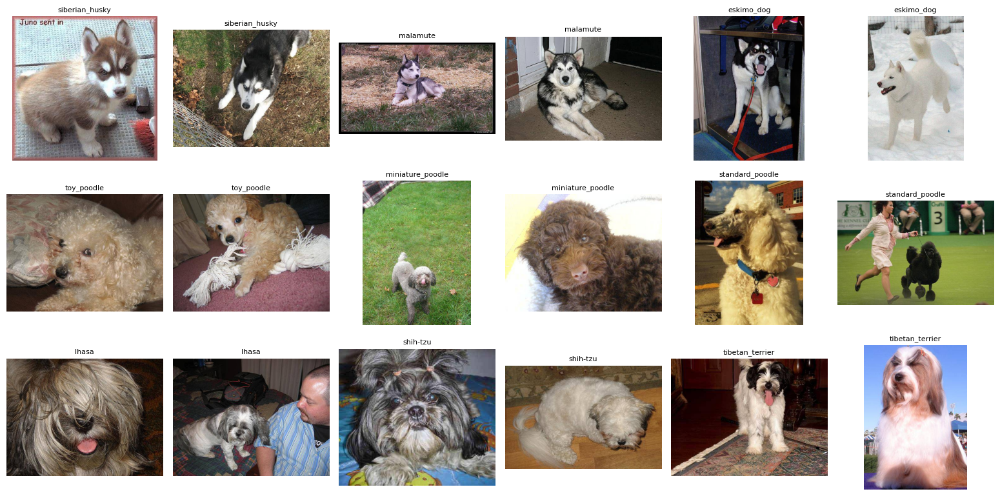

In [13]:
# Races visuellement très proches : le cœur de la difficulté "fine-grained"
GROUPS = [["siberian_husky", "malamute", "eskimo_dog"],
          ["toy_poodle", "miniature_poodle", "standard_poodle"],
          ["lhasa", "shih-tzu", "tibetan_terrier"]]
imgs, titles = [], []
for g in GROUPS:
    for b in [b for b in g if b in BREED2IDX]:
        ids = labels.index[labels.breed == b][:2]
        imgs += [train_paths[i] for i in ids]
        titles += [b] * len(ids)
show_images(imgs, titles, ncols=6)

### Observations et conséquences sur nos choix

- **Classes légèrement déséquilibrées** : de 66 images (eskimo_dog) à 126 (scottish_deerhound), moyenne 85,2, ratio max/min = 1,91. → Validation **stratifiée** ; pas de pondération des classes (déséquilibre modéré).
- **Tailles très variables** : médiane 500×375 px, de 97×102 à 3264×2562 px ; 7,7 % des images ont un côté court inférieur à 224 px. → Redimensionnement commun ; nous gardons **tout le côté court** (redimensionnement puis carré central), ce qui coupe moins le chien que le recadrage standard.
- **Format homogène** : toutes les images sont des JPEG en RGB (train et échantillon du test). La conversion RGB est conservée par sécurité.
- **Images « sales »** : humains, plusieurs chiens, chien petit ou caché. → Erreurs inévitables : il faut **éviter les probabilités extrêmes** (la log loss les punit très fort).
- **Races quasi identiques** (husky / malamute / eskimo dog, les trois caniches, lhasa / shih-tzu) : les détails qui les distinguent sont **fins** (texture du pelage, forme des oreilles). C'est précisément le point faible attendu d'AlexNet, dont le premier filtre 11×11 avance de 4 pixels à la fois : nous le testerons avec l'étude de résolution.
- Les images viennent de *Stanford Dogs*, extrait d'ImageNet : **les 120 races font partie des 1 000 classes sur lesquelles AlexNet a été pré-entraîné**.

# 4. Protocole d'évaluation

- Découpage **stratifié 80 / 20** de `train/` avec `random_state = 42` (~8 180 images d'entraînement, ~2 045 de validation, toutes les races représentées).
- Le découpage est **sauvegardé sur Drive** et rechargé à chaque exécution : **toutes les stratégies et tous les essais utilisent exactement la même validation**.
- Le test n'est jamais utilisé pour entraîner ou régler quoi que ce soit.

In [14]:
SPLIT_PATH = os.path.join(WORK_DIR, "split.csv")
if os.path.exists(SPLIT_PATH):
    split = pd.read_csv(SPLIT_PATH)
    assert (split["id"].values == labels["id"].values).all()
    print("Split rechargé depuis Drive (identique pour toutes les expériences).")
else:
    sss = StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
    _, va = next(sss.split(np.zeros(N_TRAIN), y_all))
    split = pd.DataFrame({"id": labels["id"], "breed": labels["breed"], "is_val": False})
    split.loc[va, "is_val"] = True
    split.to_csv(SPLIT_PATH, index=False)
    print("Nouveau split créé et sauvegardé :", SPLIT_PATH)

tr_idx = np.where(~split["is_val"].values)[0]
va_idx = np.where(split["is_val"].values)[0]
te_idx = np.arange(N_TRAIN, N_TRAIN + N_TEST)          # lignes du test dans le cache d'images
y_tr, y_va = y_all[tr_idx], y_all[va_idx]
va_counts = np.bincount(y_va, minlength=N_CLASSES)
print(f"train = {len(tr_idx)} images | validation = {len(va_idx)} images")
print(f"images de validation par race : min {va_counts.min()}, max {va_counts.max()}")
assert (va_counts > 0).all(), "une race manque dans la validation"

Split rechargé depuis Drive (identique pour toutes les expériences).
train = 8177 images | validation = 2045 images
images de validation par race : min 13, max 25


# 5. Décodage unique des images (cache)

Les 20 579 JPEG sont décodés **une seule fois** vers un tableau `uint8` (N, 384, 384, 3) sur le disque local (~9 Go, lu par mappage mémoire) : conversion RGB, redimensionnement du côté court à 384 px, carré central.
Ensuite, le redimensionnement vers la résolution voulue (224 px pour AlexNet, ou plus pour l'étude de résolution), la normalisation et l'augmentation de données sont faits **sur GPU**.
Lignes `0 … N_TRAIN-1` = train (ordre de `labels.csv`), puis le test dans l'ordre de `sample_submission.csv`.

décodage des images:   0%|          | 0/322 [00:00<?, ?it/s]

Cache construit en 135 s
cache : (20579, 384, 384, 3) (9.1 Go)


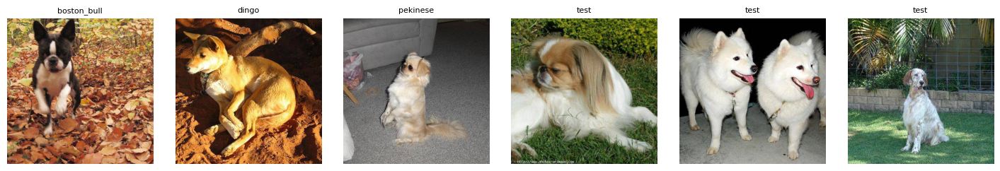

In [15]:
CACHE_SIZE = 384
CACHE_PATH = os.path.join(LOCAL_DIR, f"cache_{CACHE_SIZE}.npy")
CACHE_OK = CACHE_PATH + ".ok"
ALL_PATHS = train_paths + test_paths

class DecodeDataset(torch.utils.data.Dataset):
    """Image → RGB → côté court redimensionné à S → carré central S×S (uint8)"""
    def __init__(self, paths, size):
        self.paths, self.size = paths, size
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        S = self.size
        img = Image.open(self.paths[i])
        img.draft("RGB", (S, S))                  # décodage JPEG à échelle réduite, jamais < S
        img = img.convert("RGB")
        w, h = img.size
        s = S / min(w, h)
        nw, nh = max(S, round(w * s)), max(S, round(h * s))
        img = img.resize((nw, nh), Image.BICUBIC)
        left, top = (nw - S) // 2, (nh - S) // 2
        img = img.crop((left, top, left + S, top + S))
        return torch.from_numpy(np.asarray(img, dtype=np.uint8).copy())

if not os.path.exists(CACHE_OK):
    t0 = time.time()
    mm = np.lib.format.open_memmap(CACHE_PATH, mode="w+", dtype=np.uint8,
                                   shape=(len(ALL_PATHS), CACHE_SIZE, CACHE_SIZE, 3))
    loader = torch.utils.data.DataLoader(DecodeDataset(ALL_PATHS, CACHE_SIZE), batch_size=64,
                                         num_workers=os.cpu_count(), shuffle=False)
    pos = 0
    for b in tqdm(loader, desc="décodage des images"):
        mm[pos:pos + len(b)] = b.numpy()
        pos += len(b)
    mm.flush(); del mm
    open(CACHE_OK, "w").write("ok")
    print(f"Cache construit en {time.time() - t0:.0f} s")

cache = np.load(CACHE_PATH, mmap_mode="r")
print("cache :", cache.shape, f"({cache.nbytes / 1e9:.1f} Go)")
show_images([cache[i] for i in [0, 1, 2, N_TRAIN, N_TRAIN + 1, N_TRAIN + 2]],
            [labels.breed[0], labels.breed[1], labels.breed[2], "test", "test", "test"], ncols=6, size=2.4)

# 6. AlexNet : architecture et prétraitement

AlexNet a gagné le concours ImageNet 2012 avec 15,3 % d'erreur top-5 (contre 26,2 % pour le deuxième) et a lancé l'ère du deep learning en vision. Ses apports :
**ReLU** (entraînement bien plus rapide que tanh), **dropout** dans les couches entièrement connectées, **augmentation de données**, max-pooling **chevauchant** (fenêtre 3×3, pas de 2), et entraînement sur **GPU**.

La version de `torchvision` (64-192-384-256-256 filtres, sans normalisation LRN) correspond à la variante « une seule colonne » publiée par Krizhevsky en 2014. Ses poids ImageNet-1k officiels atteignent 56,5 % de top-1.

**Prétraitement** : la résolution d'entrée (224) et la normalisation du pré-entraînement sont **lues dans les métadonnées des poids**, pas écrites à la main.

In [16]:
WEIGHTS = models.AlexNet_Weights.IMAGENET1K_V1
PRETRAINED = True
_t = WEIGHTS.transforms()
NATIVE_RES = int(_t.crop_size[0])
MEAN, STD = list(_t.mean), list(_t.std)
print(f"Résolution d'entrée native : {NATIVE_RES} px | normalisation : mean = {MEAN}, std = {STD}")

def load_alexnet():
    if not PRETRAINED:
        torch.manual_seed(0)      # mode test sans poids : même réseau à chaque appel
    return models.alexnet(weights=WEIGHTS if PRETRAINED else None)

# Tableau couche par couche (sorties pour une image 224×224)
ref = load_alexnet().eval()
NAMES = {"features.0": "conv1", "features.3": "conv2", "features.6": "conv3", "features.8": "conv4",
         "features.10": "conv5", "features.12": "pool5", "classifier.1": "fc6", "classifier.4": "fc7",
         "classifier.6": "fc8"}
rows, h = [], torch.zeros(1, 3, NATIVE_RES, NATIVE_RES)
with torch.no_grad():
    for prefix, seq in [("features", ref.features), ("avgpool", None), ("classifier", ref.classifier)]:
        if seq is None:
            h = torch.flatten(ref.avgpool(h), 1)
            rows.append({"couche": "avgpool + flatten", "type": "AdaptiveAvgPool2d(6×6)", "sortie": tuple(h.shape[1:]), "paramètres": 0})
            continue
        for i, layer in enumerate(seq):
            h = layer(h)
            key = f"{prefix}.{i}"
            desc = layer.__class__.__name__
            if isinstance(layer, nn.Conv2d):
                desc = f"Conv {layer.kernel_size[0]}×{layer.kernel_size[1]}, pas {layer.stride[0]}, {layer.out_channels} filtres"
            elif isinstance(layer, nn.MaxPool2d):
                desc = f"MaxPool {layer.kernel_size}×{layer.kernel_size}, pas {layer.stride}"
            elif isinstance(layer, nn.Linear):
                desc = f"Linear {layer.in_features} → {layer.out_features}"
            rows.append({"couche": NAMES.get(key, key), "type": desc, "sortie": tuple(h.shape[1:]),
                         "paramètres": sum(p.numel() for p in layer.parameters())})
arch = pd.DataFrame(rows)
TOTAL_PARAMS = arch["paramètres"].sum()
arch["% du total"] = arch["paramètres"] / TOTAL_PARAMS * 100
display(arch[arch["type"] != "ReLU"].reset_index(drop=True))

conv_p = sum(p.numel() for p in ref.features.parameters())
fc_p = sum(p.numel() for p in ref.classifier.parameters())
print(f"Total : {TOTAL_PARAMS / 1e6:.1f} M paramètres ({TOTAL_PARAMS * 4 / 1e6:.0f} Mo en float32)")
print(f"  convolutions (5 couches) : {conv_p / 1e6:.2f} M = {conv_p / TOTAL_PARAMS * 100:.1f} %")
print(f"  entièrement connectées (3 couches) : {fc_p / 1e6:.2f} M = {fc_p / TOTAL_PARAMS * 100:.1f} %")

Résolution d'entrée native : 224 px | normalisation : mean = [0.485, 0.456, 0.406], std = [0.229, 0.224, 0.225]
Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:01<00:00, 152MB/s]


,couche,type,sortie,paramètres,% du total
0,conv1,"Conv 11×11, pas 4, 64 filtres","(64, 55, 55)",23296,0.0381
1,features.2,"MaxPool 3×3, pas 2","(64, 27, 27)",0,0.0000
2,conv2,"Conv 5×5, pas 1, 192 filtres","(192, 27, 27)",307392,0.5031
3,features.5,"MaxPool 3×3, pas 2","(192, 13, 13)",0,0.0000
4,conv3,"Conv 3×3, pas 1, 384 filtres","(384, 13, 13)",663936,1.0866
5,conv4,"Conv 3×3, pas 1, 256 filtres","(256, 13, 13)",884992,1.4484
6,conv5,"Conv 3×3, pas 1, 256 filtres","(256, 13, 13)",590080,0.9657
7,pool5,"MaxPool 3×3, pas 2","(256, 6, 6)",0,0.0000
8,avgpool + flatten,AdaptiveAvgPool2d(6×6),"(9216,)",0,0.0000
9,classifier.0,Dropout,"(9216,)",0,0.0000


Total : 61.1 M paramètres (244 Mo en float32)
  convolutions (5 couches) : 2.47 M = 4.0 %
  entièrement connectées (3 couches) : 58.63 M = 96.0 %


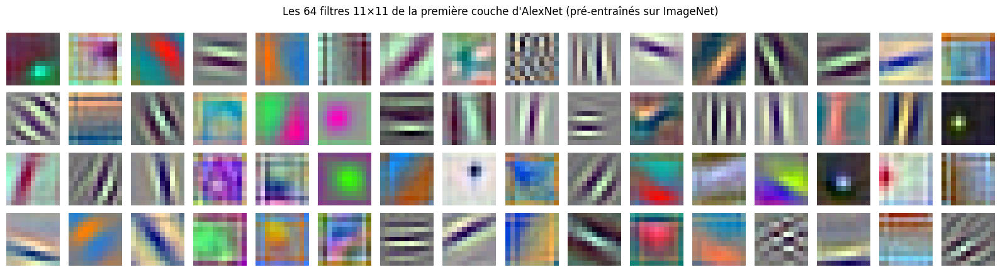

In [17]:
# Les 64 filtres de conv1 (11×11×3) appris sur ImageNet : détecteurs de contours orientés et de couleurs
w = ref.features[0].weight.detach().clone()
w = (w - w.amin(dim=(1, 2, 3), keepdim=True)) / (w.amax(dim=(1, 2, 3), keepdim=True) - w.amin(dim=(1, 2, 3), keepdim=True) + 1e-8)
fig, axes = plt.subplots(4, 16, figsize=(16, 4.4))
for ax, f in zip(axes.ravel(), w):
    ax.imshow(f.permute(1, 2, 0).numpy(), interpolation="nearest"); ax.axis("off")
fig.suptitle("Les 64 filtres 11×11 de la première couche d'AlexNet (pré-entraînés sur ImageNet)")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "conv1_filtres.png"), dpi=120); plt.show()
del ref

**Lecture** : environ **96 % des paramètres sont dans les 3 couches entièrement connectées** (`fc6` seule en contient ~38 M, car elle relie 6×6×256 = 9 216 valeurs à 4 096 neurones). Les 5 couches de convolution, qui « voient » réellement l'image, n'en contiennent que ~2,5 M.
Les filtres de `conv1` montrent des détecteurs de contours orientés, de fréquences et de couleurs : ce sont ces briques génériques qui rendent le transfer learning possible.

# 7. Extraction des features (plusieurs couches, plusieurs résolutions)

Un seul passage du réseau gelé donne toutes les couches : `pool5` (moyenne globale 256 dim. et version aplatie 9 216 dim.), `fc6` et `fc7` (4 096 dim., après ReLU).
Chaque image est passée **avec son miroir horizontal** (utilisé dans l'optimisation).
L'extraction est faite à 224 px (benchmark) puis à 288 et 352 px (étude de résolution, section 11). AlexNet accepte ces tailles grâce à son `AdaptiveAvgPool2d(6×6)` : `fc6` reçoit toujours 9 216 valeurs.

In [18]:
LAYER_DIM = {"pool5_gap": 256, "pool5": 9216, "fc6": 4096, "fc7": 4096}
RES_LIST = [224, 288, 352]
mean_t = torch.tensor(MEAN, device=DEVICE).view(1, 3, 1, 1)
std_t = torch.tensor(STD, device=DEVICE).view(1, 3, 1, 1)

def to01(xb):
    """uint8 (B, S, S, 3) → float [0, 1] (B, 3, S, S) sur GPU"""
    return xb.to(DEVICE, non_blocking=True).permute(0, 3, 1, 2).float().div_(255.0)

def resize(x, size):
    return x if x.shape[-1] == size else F.interpolate(x, size=(size, size), mode="bilinear", antialias=True, align_corners=False)

def normalize(x):
    return ((x - mean_t) / std_t).contiguous(memory_format=torch.channels_last)

def alexnet_layers(m, x, layers):
    out = {}
    h = m.features(x)                                   # pool5 : (B, 256, 6, 6) à 224 px
    if "pool5_gap" in layers:
        out["pool5_gap"] = h.mean(dim=(2, 3))
    h = torch.flatten(m.avgpool(h), 1)                  # (B, 9216)
    if "pool5" in layers:
        out["pool5"] = h
    h = m.classifier[0:3](h)                            # Dropout (inactif en eval) → fc6 → ReLU
    out["fc6"] = h
    out["fc7"] = m.classifier[3:6](h)                   # Dropout → fc7 → ReLU
    return out

def fpath(layer, res, flip):
    return os.path.join(FEAT_DIR, f"{layer}_r{res}{'_flip' if flip else ''}.npy")

@torch.no_grad()
def extract(res, bs=256):
    done = os.path.join(FEAT_DIR, f"r{res}.json")
    if os.path.exists(done):
        return json.load(open(done))
    layers = ["pool5_gap", "pool5", "fc6", "fc7"] if res == NATIVE_RES else ["pool5_gap", "fc6", "fc7"]
    m = load_alexnet().eval().to(DEVICE).to(memory_format=torch.channels_last)
    N = len(cache)
    mms = {(l, fl): np.lib.format.open_memmap(fpath(l, res, fl), mode="w+", dtype=np.float16, shape=(N, LAYER_DIM[l]))
           for l in layers for fl in (False, True)}
    if DEVICE == "cuda": torch.cuda.synchronize()
    t0 = time.time()
    for i in tqdm(range(0, N, bs), desc=f"features AlexNet {res} px"):
        x = normalize(resize(to01(torch.from_numpy(np.ascontiguousarray(cache[i:i + bs]))), res))
        for fl in (False, True):
            with torch.autocast("cuda", dtype=torch.float16, enabled=DEVICE == "cuda"):
                o = alexnet_layers(m, torch.flip(x, dims=[3]) if fl else x, layers)
            for l in layers:
                mms[(l, fl)][i:i + bs] = o[l].float().cpu().numpy()
    if DEVICE == "cuda": torch.cuda.synchronize()
    meta = {"res": res, "layers": layers, "t_extract_s": time.time() - t0}
    for a in mms.values():
        a.flush()
    del mms, m
    json.dump(meta, open(done, "w"))
    return meta

def load_feats(layer, res=NATIVE_RES):
    """(features, features du miroir) — lues par mappage mémoire (pas de surcharge de la RAM)"""
    return np.load(fpath(layer, res, False), mmap_mode="r"), np.load(fpath(layer, res, True), mmap_mode="r")

EXTRACT_META = {NATIVE_RES: extract(NATIVE_RES)}
print(f"Extraction {NATIVE_RES} px (train + test, image + miroir, 4 couches) : {EXTRACT_META[NATIVE_RES]['t_extract_s']:.0f} s")

features AlexNet 224 px:   0%|          | 0/81 [00:00<?, ?it/s]

Extraction 224 px (train + test, image + miroir, 4 couches) : 51 s


In [19]:
# Mesures de taille et de vitesse du modèle DÉPLOYABLE de chaque stratégie (backbone tronqué + couche 120 classes)
SPEED_PATH = os.path.join(WORK_DIR, "speed.json")
SPEED = json.load(open(SPEED_PATH)) if os.path.exists(SPEED_PATH) else {}

def deployable(variant):
    m = load_alexnet()
    if variant == "pool5_gap":
        return nn.Sequential(m.features, nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(256, N_CLASSES))
    if variant == "pool5":
        return nn.Sequential(m.features, m.avgpool, nn.Flatten(), nn.Linear(9216, N_CLASSES))
    if variant == "fc6":
        return nn.Sequential(m.features, m.avgpool, nn.Flatten(), *m.classifier[0:3], nn.Linear(4096, N_CLASSES))
    return nn.Sequential(m.features, m.avgpool, nn.Flatten(), *m.classifier[0:6], nn.Linear(4096, N_CLASSES))   # fc7 / fine-tuning

@torch.no_grad()
def measure_latency(model, res, device, batch, reps, amp=False):
    model = model.to(device).eval()
    x = torch.randn(batch, 3, res, res, device=device).contiguous(memory_format=torch.channels_last)
    def run():
        with torch.autocast("cuda", dtype=torch.float16, enabled=amp and device == "cuda"):
            model(x)
    for _ in range(3 if device == "cuda" else 1):
        run()
    if device == "cuda": torch.cuda.synchronize()
    t0 = time.perf_counter()
    for _ in range(reps):
        run()
    if device == "cuda": torch.cuda.synchronize()
    return (time.perf_counter() - t0) / (reps * batch) * 1000      # ms / image

def speed(variant, res=NATIVE_RES):
    key = f"{variant}_r{res}"
    if key not in SPEED:
        net = deployable(variant).to(memory_format=torch.channels_last)
        s = {"params": int(sum(p.numel() for p in net.parameters()))}
        s["ms_gpu_batch_fp16"] = measure_latency(net, res, "cuda", 128, 10, amp=True) if DEVICE == "cuda" else None
        s["ms_gpu_bs1_fp32"] = measure_latency(net, res, "cuda", 1, 50) if DEVICE == "cuda" else None
        torch.set_num_threads(os.cpu_count())
        s["ms_cpu_bs1"] = measure_latency(net, res, "cpu", 1, 10)
        SPEED[key] = s
        json.dump(SPEED, open(SPEED_PATH, "w"), indent=1)
        del net
    return SPEED[key]

display(pd.DataFrame({v: speed(v) for v in ["pool5_gap", "pool5", "fc6", "fc7"]}).T)

,params,ms_gpu_batch_fp16,ms_gpu_bs1_fp32,ms_cpu_bs1
pool5_gap,2.5005e+06,0.1148,1.3797,13.6884
pool5,3.5757e+06,0.1198,1.3820,38.3057
fc6,4.0714e+07,0.1279,2.2215,25.9362
fc7,5.7495e+07,0.1340,2.4450,31.2141


# 8. Tête de classification commune (stratégies S1 à S4)

**Régression logistique multinomiale** sur les features standardisées (moyenne / écart-type de la partie entraînement) : `Linear(D, 120)` + softmax, entraînée par AdamW (taux d'apprentissage en cosinus).
- **Early stopping** sur la log loss de validation ; l'époque retenue sert à réentraîner sur 100 % du train.
- **Mêmes hyperparamètres pour toutes les couches** (`HEAD_CFG`) : seule la couche d'extraction change.
- Log loss calculée avec la formule Kaggle, à partir des logits.

In [20]:
HEAD_CFG = dict(epochs=40, lr=1e-3, wd=1e-4, dropout=0.0, bs=256, label_smoothing=0.0)

class LinearHead(nn.Module):
    def __init__(self, mu, sd, n_classes, dropout):
        super().__init__()
        self.register_buffer("mu", mu)
        self.register_buffer("sd", sd)
        self.drop = nn.Dropout(dropout)
        self.fc = nn.Linear(mu.numel(), n_classes)
    def forward(self, x):
        return self.fc(self.drop((x - self.mu) / self.sd))

def nll(logits, y, T=1.0):
    """Multi-class log loss (formule Kaggle) à partir des logits, avec température T."""
    return float(-log_softmax(logits / T, axis=1)[np.arange(len(y)), y].mean())

def acc(logits, y):
    return float((logits.argmax(1) == y).mean())

def ece(logits, y, n_bins=15):
    """Expected Calibration Error : écart moyen entre confiance annoncée et taux de réussite réel."""
    p = softmax(logits, 1); conf = p.max(1); ok = p.argmax(1) == y
    e = 0.0
    for lo, hi in zip(np.linspace(0, 1, n_bins + 1)[:-1], np.linspace(0, 1, n_bins + 1)[1:]):
        mk = (conf > lo) & (conf <= hi)
        if mk.any():
            e += mk.mean() * abs(ok[mk].mean() - conf[mk].mean())
    return float(e)

@torch.no_grad()
def predict_logits(head, X, bs=4096):
    head.eval()
    out = [head(torch.as_tensor(np.asarray(X[i:i + bs]), dtype=torch.float32, device=DEVICE)).cpu().numpy()
           for i in range(0, len(X), bs)]
    return np.concatenate(out).astype(np.float64)

def train_head(Xtr, ytr, Xva=None, yva=None, epochs=40, lr=1e-3, wd=1e-4, dropout=0.0, bs=256,
               label_smoothing=0.0, stop_at=None, seed=SEED, Xva_views=None):
    """Avec validation : early stopping sur la log loss de validation.
       Sans validation (réentraînement final) : arrêt à l'époque `stop_at` trouvée sur la validation.
       Xva_views : liste de matrices (une par vue) → la validation moyenne les logits des vues (TTA)."""
    seed_everything(seed)
    X = torch.as_tensor(np.asarray(Xtr), device=DEVICE).float()          # conversion float32 directement sur GPU
    if Xva_views is None and Xva is not None:
        Xva_views = [Xva]
    Y = torch.as_tensor(ytr, dtype=torch.long, device=DEVICE)
    sd = X.std(0)
    sd = sd.clamp_min(0.05 * sd.median() + 1e-6)   # plancher : une unité quasi « morte » sur le train ne doit pas
                                                    # être amplifiée x1e6 si elle s'active sur d'autres images
    head = LinearHead(X.mean(0), sd, N_CLASSES, dropout).to(DEVICE)
    opt = torch.optim.AdamW(head.parameters(), lr=lr, weight_decay=wd)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs * math.ceil(len(X) / bs))
    gen = torch.Generator().manual_seed(seed)
    n_tr_eval = min(3000, len(X))
    hist, best = [], (np.inf, None, 0)
    for ep in range(1, epochs + 1):
        head.train()
        perm = torch.randperm(len(X), generator=gen).to(DEVICE)
        for i in range(0, len(X), bs):
            b = perm[i:i + bs]
            loss = F.cross_entropy(head(X[b]), Y[b], label_smoothing=label_smoothing)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step(); sched.step()
        rec = {"epoch": ep, "train_loss": nll(predict_logits(head, Xtr[:n_tr_eval]), ytr[:n_tr_eval])}
        if Xva_views is not None:
            lv = np.mean([predict_logits(head, V) for V in Xva_views], axis=0)
            rec.update(val_loss=nll(lv, yva), val_acc=acc(lv, yva))
            if rec["val_loss"] < best[0]:
                best = (rec["val_loss"], copy.deepcopy(head.state_dict()), ep)
        hist.append(rec)
        if stop_at is not None and ep >= stop_at:
            break
    del X
    if Xva_views is not None and stop_at is None:
        head.load_state_dict(best[1])
        return head, pd.DataFrame(hist), best[2]
    return head, pd.DataFrame(hist), (stop_at or epochs)

# 9. Fine-tuning (stratégies S5 et S6)

- **Initialisation de la nouvelle couche `fc8` (120 classes) avec la régression logistique de S4** (*linear probing puis fine-tuning*). Une couche initialisée au hasard enverrait au départ de gros gradients aléatoires qui abîment les poids pré-entraînés ; partir d'une tête déjà bonne évite cela.
- **Taux d'apprentissage faibles et différenciés** (AdamW) : 1e-4 pour les couches pré-entraînées, 3e-4 pour `fc8` ; 1 époque d'échauffement puis cosinus ; précision mixte fp16.
- **Augmentation de données sur GPU** (utile ici, contrairement aux features gelées) : recadrage aléatoire (30 à 100 % de la surface, rapport 3/4 à 4/3), miroir horizontal, légère variation de luminosité / contraste.
- Le **dropout 0,5 d'origine** d'AlexNet avant `fc6` et `fc7` reste actif pendant l'entraînement (réglable : `FT_CFG["dropout"]`).
- **Early stopping** : on évalue la log loss de validation à chaque époque (y compris l'époque 0, avant tout fine-tuning) et on garde le meilleur état ; les gradients sont écrêtés (norme 2).
- Si l'époque retenue est 0, le fine-tuning n'a rien apporté par rapport à la tête logistique. Essayez alors des taux plus faibles (`lr_fc = lr_conv = 3e-5`) et/ou `dropout = 0.2` dans `FT_CFG`, puis relancez la cellule : un nouveau réglage relance automatiquement l'entraînement (les anciens résultats restent sur Drive). Notez chaque essai : c'est aussi de l'optimisation mesurée.
- À la fin, les logits de validation et de test sont calculés pour plusieurs « vues » (image entière, miroir, 10 crops) et **sauvegardés sur Drive** : une relance ne réentraîne rien.

S5 (partiel) gèle les 5 convolutions et réentraîne `fc6`, `fc7`, `fc8` ; S6 (complet) réentraîne tout.

In [21]:
FT_CFG = dict(epochs=10, bs=128, lr_conv=1e-4, lr_fc=1e-4, lr_head=3e-4, wd=1e-2, warmup=1,
              scale=(0.30, 1.0), ratio=(3 / 4, 4 / 3), jitter=0.2,
              dropout=0.5)   # dropout d'origine d'AlexNet avant fc6 et fc7 (si l'époque 0 reste la meilleure, essayer 0.2)
CROP_VIEWS = [f"crop{k}{s}" for k in range(5) for s in ("", "_flip")]     # 10 crops : centre + 4 coins, x miroir
ALL_VIEWS = ["full", "full_flip"] + CROP_VIEWS

def fold_head(head):
    """Intègre la standardisation de la tête logistique dans une couche Linear équivalente : W' = W/sd, b' = b − W·mu/sd"""
    W = head.fc.weight.detach() / head.sd[None, :]
    b = head.fc.bias.detach() - (head.fc.weight.detach() * (head.mu / head.sd)[None, :]).sum(1)
    return W, b

def make_ft_model(head_init, train_convs, dropout=0.5):
    m = load_alexnet()
    m.classifier[0].p = m.classifier[3].p = dropout
    m.classifier[6] = nn.Linear(4096, N_CLASSES)
    if head_init is not None:                       # sinon : fc8 initialisée au hasard
        W, b = fold_head(head_init)
        with torch.no_grad():
            m.classifier[6].weight.copy_(W.cpu()); m.classifier[6].bias.copy_(b.cpu())
    for p in m.features.parameters():
        p.requires_grad_(train_convs)
    return m.to(DEVICE).to(memory_format=torch.channels_last)

def gpu_augment(xb, res, cfg, gen):
    """Recadrage aléatoire + miroir + luminosité/contraste, par lot, sur GPU (transformation affine)."""
    x = resize(to01(xb), round(res * 256 / 224))
    B = x.shape[0]
    area = torch.empty(B).uniform_(*cfg["scale"], generator=gen)
    r = torch.exp(torch.empty(B).uniform_(math.log(cfg["ratio"][0]), math.log(cfg["ratio"][1]), generator=gen))
    sw, sh = torch.sqrt(area * r).clamp(max=1), torch.sqrt(area / r).clamp(max=1)
    tx = (torch.rand(B, generator=gen) * 2 - 1) * (1 - sw)
    ty = (torch.rand(B, generator=gen) * 2 - 1) * (1 - sh)
    flip = torch.where(torch.rand(B, generator=gen) < 0.5, -1.0, 1.0)
    theta = torch.zeros(B, 2, 3)
    theta[:, 0, 0], theta[:, 0, 2], theta[:, 1, 1], theta[:, 1, 2] = sw * flip, tx, sh, ty
    grid = F.affine_grid(theta.to(DEVICE), (B, 3, res, res), align_corners=False)
    x = F.grid_sample(x, grid, mode="bilinear", padding_mode="reflection", align_corners=False)
    if cfg["jitter"] > 0:
        j = cfg["jitter"]
        bri = (1 + (torch.rand(B, 1, 1, 1, generator=gen) * 2 - 1) * j).to(DEVICE)
        con = (1 + (torch.rand(B, 1, 1, 1, generator=gen) * 2 - 1) * j).to(DEVICE)
        mu = x.mean(dim=(1, 2, 3), keepdim=True)
        x = (((x - mu) * con + mu) * bri).clamp(0, 1)
    return normalize(x)

def make_view(full, big, v, res):
    """Vue « full » = image entière ; « cropK » = crop res×res (centre, 4 coins) de l'image agrandie à res·256/224 ; « _flip » = miroir."""
    if v.startswith("full"):
        inp = full
    else:
        S = big.shape[-1]
        t, l = {0: ((S - res) // 2, (S - res) // 2), 1: (0, 0), 2: (0, S - res), 3: (S - res, 0), 4: (S - res, S - res)}[int(v[4])]
        inp = big[:, :, t:t + res, l:l + res]
    return torch.flip(inp, dims=[3]) if v.endswith("_flip") else inp

@torch.no_grad()
def predict_views(model, idx, res, views=ALL_VIEWS, bs=256):
    """Logits pour plusieurs vues de chaque image : entière, miroir, 10 crops (style AlexNet 2012)."""
    model.eval()
    out = {v: [] for v in views}
    S = round(res * 256 / 224)
    for i in range(0, len(idx), bs):
        x01 = to01(torch.from_numpy(cache[idx[i:i + bs]]))
        full = resize(x01, res)
        big = resize(x01, S) if any(v.startswith("crop") for v in views) else None
        for v in views:
            inp = make_view(full, big, v, res)
            with torch.autocast("cuda", dtype=torch.float16, enabled=DEVICE == "cuda"):
                out[v].append(model(normalize(inp)).float().cpu().numpy())
    return {v: np.concatenate(o).astype(np.float64) for v, o in out.items()}

def finetune(tag, cfg, train_idx, head_init, train_convs, with_val=True, fixed_epochs=None, res=NATIVE_RES, seed=SEED):
    """Fine-tuning d'AlexNet. Résultats (logits val/test par vue + historique) sauvegardés sur Drive.
       Le nom du fichier contient une empreinte de cfg : modifier FT_CFG relance automatiquement l'entraînement."""
    import hashlib
    base = os.path.join(FT_DIR, f"{tag}_{hashlib.md5(json.dumps(cfg, sort_keys=True).encode()).hexdigest()[:6]}")
    if os.path.exists(base + ".npz") and os.path.exists(base + ".json"):
        print(f"[{tag}] résultats rechargés depuis Drive")
        return json.load(open(base + ".json")), dict(np.load(base + ".npz"))
    seed_everything(seed)
    model = make_ft_model(head_init, train_convs, cfg["dropout"])
    groups = [{"params": list(model.classifier[1].parameters()) + list(model.classifier[4].parameters()), "lr": cfg["lr_fc"]},
              {"params": model.classifier[6].parameters(), "lr": cfg["lr_head"]}]
    if train_convs:
        groups.append({"params": model.features.parameters(), "lr": cfg["lr_conv"]})
    opt = torch.optim.AdamW(groups, weight_decay=cfg["wd"])
    E = cfg["epochs"] if fixed_epochs is None else fixed_epochs
    spe = math.ceil(len(train_idx) / cfg["bs"]); total, warm = E * spe, cfg["warmup"] * spe
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: (s + 1) / warm if s < warm else 0.5 * (1 + math.cos(math.pi * (s - warm) / max(1, total - warm))))
    scaler = torch.amp.GradScaler("cuda", enabled=DEVICE == "cuda")
    gen = torch.Generator().manual_seed(seed)
    mix = cfg.get("mixup", 0.0)                       # mixup : mélange de 2 images et de leurs étiquettes
    rng_mix = np.random.RandomState(seed)
    tr_eval = np.sort(np.random.RandomState(seed).choice(train_idx, min(2000, len(train_idx)), replace=False))
    hist, best = [], (np.inf, None, 0)
    if DEVICE == "cuda": torch.cuda.synchronize()
    def evaluate(ep):
        rec = {"epoch": ep, "train_loss": nll(predict_views(model, tr_eval, res, ["full"])["full"], y_all[tr_eval])}
        if with_val:
            lv = predict_views(model, va_idx, res, ["full"])["full"]
            rec.update(val_loss=nll(lv, y_va), val_acc=acc(lv, y_va))
        return rec
    if with_val:                      # époque 0 = tête logistique seule : le fine-tuning ne peut pas faire pire
        rec = evaluate(0); hist.append(rec)
        best = (rec["val_loss"], {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}, 0)
        print(f"[{tag}] époque  0 (avant fine-tuning) | val_loss {rec['val_loss']:.4f} | val_acc {rec['val_acc']:.4f}")
    t0 = time.time()
    for ep in range(1, E + 1):
        model.train()
        perm = torch.randperm(len(train_idx), generator=gen).numpy()
        for i in tqdm(range(0, len(perm), cfg["bs"]), desc=f"[{tag}] époque {ep}/{E}", leave=False):
            bidx = train_idx[np.sort(perm[i:i + cfg["bs"]])]
            x = gpu_augment(torch.from_numpy(cache[bidx]), res, cfg, gen)
            y = torch.as_tensor(y_all[bidx], device=DEVICE)
            if mix > 0:
                lam = float(rng_mix.beta(mix, mix))
                j = torch.randperm(len(y), generator=gen).to(DEVICE)
                x = lam * x + (1 - lam) * x[j]
            with torch.autocast("cuda", dtype=torch.float16, enabled=DEVICE == "cuda"):
                out = model(x)
                loss = F.cross_entropy(out, y) if mix <= 0 else lam * F.cross_entropy(out, y) + (1 - lam) * F.cross_entropy(out, y[j])
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 2.0)     # protège les poids pré-entraînés des pics de gradient
            scaler.step(opt); scaler.update(); sched.step()
        rec = evaluate(ep)
        if with_val:
            if rec["val_loss"] < best[0]:
                best = (rec["val_loss"], {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}, ep)
        hist.append(rec)
        print(f"[{tag}] époque {ep:2d} | " + " | ".join(f"{k} {v:.4f}" for k, v in rec.items() if k != "epoch"))
    if DEVICE == "cuda": torch.cuda.synchronize()
    t_train = time.time() - t0
    if with_val:
        model.load_state_dict(best[1])
    arrs = {}
    if with_val:
        arrs.update({f"val_{v}": a for v, a in predict_views(model, va_idx, res).items()})
    arrs.update({f"test_{v}": a for v, a in predict_views(model, te_idx, res).items()})
    info = {"tag": tag, "best_epoch": best[2] if with_val else E, "t_train_s": t_train, "res": res,
            "train_convs": train_convs, "trainable_params": int(sum(p.numel() for p in model.parameters() if p.requires_grad)),
            "hist": hist}
    np.savez(base + ".npz", **arrs)
    json.dump(info, open(base + ".json", "w"))
    del model
    if DEVICE == "cuda": torch.cuda.empty_cache()
    return info, arrs

def lp_head(res, idx, stop_at=None):
    """Régression logistique sur fc7 (protocole S4) : sert d'initialisation à fc8 pour le fine-tuning."""
    f, _ = load_feats("fc7", res)
    if stop_at is None:
        head, _, ep = train_head(f[idx], y_all[idx], f[va_idx], y_va, **HEAD_CFG)
        return head, ep
    head, _, _ = train_head(f[idx], y_all[idx], stop_at=stop_at, **HEAD_CFG)
    return head, stop_at

# 10. Benchmark des stratégies de transfer learning

Protocole **identique** : même split, image entière à 224 px, **sans miroir ni TTA**. Seule la stratégie change.

- *Temps d'entraînement* : S1–S4 = extraction des features du train + entraînement de la tête ; S5–S6 = durée du fine-tuning.
- *Inférence* : mesurée sur le modèle déployable complet (section 7). S4, S5 et S6 ont la même architecture, donc la même vitesse.

In [22]:
STRATS = {"S1": ("extraction pool5 + pooling global (256)", "pool5_gap"),
          "S2": ("extraction pool5 aplatie (9216)", "pool5"),
          "S3": ("extraction fc6 (4096)", "fc6"),
          "S4": ("extraction fc7 (4096)", "fc7")}
HEADS, HISTS, VAL_BENCH, TEST_BENCH, BEST_EP = {}, {}, {}, {}, {}
rows = []
t_ext_train = EXTRACT_META[NATIVE_RES]["t_extract_s"] * N_TRAIN / len(cache) / 2
for s, (desc, layer) in STRATS.items():
    f, _ = load_feats(layer)
    t0 = time.time()
    head, hist, ep = train_head(f[tr_idx], y_tr, f[va_idx], y_va, **HEAD_CFG)
    t_head = time.time() - t0
    lv = predict_logits(head, f[va_idx])
    HEADS[s], HISTS[s], VAL_BENCH[s], BEST_EP[s] = head, hist, lv, ep
    TEST_BENCH[s] = predict_logits(head, f[te_idx])
    sp = speed(layer)
    rows.append({"Code": s, "Stratégie": desc, "Paramètres (M)": sp["params"] / 1e6,
                 "Paramètres entraînés (M)": (LAYER_DIM[layer] + 1) * N_CLASSES / 1e6,
                 "Log Loss val": nll(lv, y_va), "Accuracy val": acc(lv, y_va),
                 "Confiance moyenne": float(softmax(lv, 1).max(1).mean()), "ECE": ece(lv, y_va),
                 "Époque retenue": ep, "Temps entraînement (s)": t_ext_train + t_head,
                 "Inférence GPU lot fp16 (ms/img)": sp["ms_gpu_batch_fp16"],
                 "Inférence GPU 1 img (ms)": sp["ms_gpu_bs1_fp32"], "Inférence CPU 1 img (ms)": sp["ms_cpu_bs1"]})
    print(f"{s} {desc:42s} logloss = {rows[-1]['Log Loss val']:.4f} | acc = {rows[-1]['Accuracy val']:.4f} | époque {ep}")

S1 extraction pool5 + pooling global (256)    logloss = 1.7700 | acc = 0.5164 | époque 40
S2 extraction pool5 aplatie (9216)            logloss = 2.1761 | acc = 0.4650 | époque 4
S3 extraction fc6 (4096)                      logloss = 1.5532 | acc = 0.5716 | époque 3
S4 extraction fc7 (4096)                      logloss = 1.5279 | acc = 0.5790 | époque 4


In [23]:
# S5 / S6 : fine-tuning partiel et complet (≈ 4-6 min chacun sur T4)
FT_RUNS = {}
for s, desc, convs in [("S5", "fine-tuning partiel (convolutions gelées)", False),
                       ("S6", "fine-tuning complet", True)]:
    info, arrs = finetune(f"{s}_r{NATIVE_RES}", FT_CFG, tr_idx, HEADS["S4"], train_convs=convs)
    FT_RUNS[s] = (info, arrs)
    lv = arrs["val_full"]
    VAL_BENCH[s], TEST_BENCH[s], BEST_EP[s] = lv, arrs["test_full"], info["best_epoch"]
    HISTS[s] = pd.DataFrame(info["hist"])
    sp = speed("fc7")
    if info["best_epoch"] == 0:
        desc = desc + " — aucun gain (époque 0)"
    rows.append({"Code": s, "Stratégie": desc, "Paramètres (M)": sp["params"] / 1e6,
                 "Paramètres entraînés (M)": info["trainable_params"] / 1e6,
                 "Log Loss val": nll(lv, y_va), "Accuracy val": acc(lv, y_va),
                 "Confiance moyenne": float(softmax(lv, 1).max(1).mean()), "ECE": ece(lv, y_va),
                 "Époque retenue": info["best_epoch"], "Temps entraînement (s)": info["t_train_s"],
                 "Inférence GPU lot fp16 (ms/img)": sp["ms_gpu_batch_fp16"],
                 "Inférence GPU 1 img (ms)": sp["ms_gpu_bs1_fp32"], "Inférence CPU 1 img (ms)": sp["ms_cpu_bs1"]})
    print(f"{s} {desc:42s} logloss = {rows[-1]['Log Loss val']:.4f} | acc = {rows[-1]['Accuracy val']:.4f} | époque {info['best_epoch']}")

bench = pd.DataFrame(rows).sort_values("Log Loss val").reset_index(drop=True)
bench.to_csv(os.path.join(WORK_DIR, "benchmark_strategies.csv"), index=False)
display(bench.style.format(precision=3).background_gradient(subset=["Log Loss val"], cmap="RdYlGn_r")
                   .background_gradient(subset=["Accuracy val"], cmap="RdYlGn"))

[S5_r224] résultats rechargés depuis Drive
S5 fine-tuning partiel (convolutions gelées) — aucun gain (époque 0) logloss = 1.5279 | acc = 0.5785 | époque 0
[S6_r224] résultats rechargés depuis Drive
S6 fine-tuning complet — aucun gain (époque 0) logloss = 1.5279 | acc = 0.5785 | époque 0


,Code,Stratégie,Paramètres (M),Paramètres entraînés (M),Log Loss val,Accuracy val,Confiance moyenne,ECE,Époque retenue,Temps entraînement (s),Inférence GPU lot fp16 (ms/img),Inférence GPU 1 img (ms),Inférence CPU 1 img (ms)
0,S6,fine-tuning complet — aucun gain (époque 0),57.495,57.495,1.528,0.578,0.628,0.050,0,96.520,0.134,2.445,31.214
1,S5,fine-tuning partiel (convolutions gelées) — aucun gain (époque 0),57.495,55.026,1.528,0.578,0.628,0.050,0,79.337,0.134,2.445,31.214
2,S4,extraction fc7 (4096),57.495,0.492,1.528,0.579,0.628,0.051,4,17.192,0.134,2.445,31.214
3,S3,extraction fc6 (4096),40.714,0.492,1.553,0.572,0.624,0.059,3,17.200,0.128,2.222,25.936
4,S1,extraction pool5 + pooling global (256),2.501,0.031,1.770,0.516,0.465,0.051,40,15.185,0.115,1.380,13.688
5,S2,extraction pool5 aplatie (9216),3.576,1.106,2.176,0.465,0.610,0.145,4,21.895,0.120,1.382,38.306


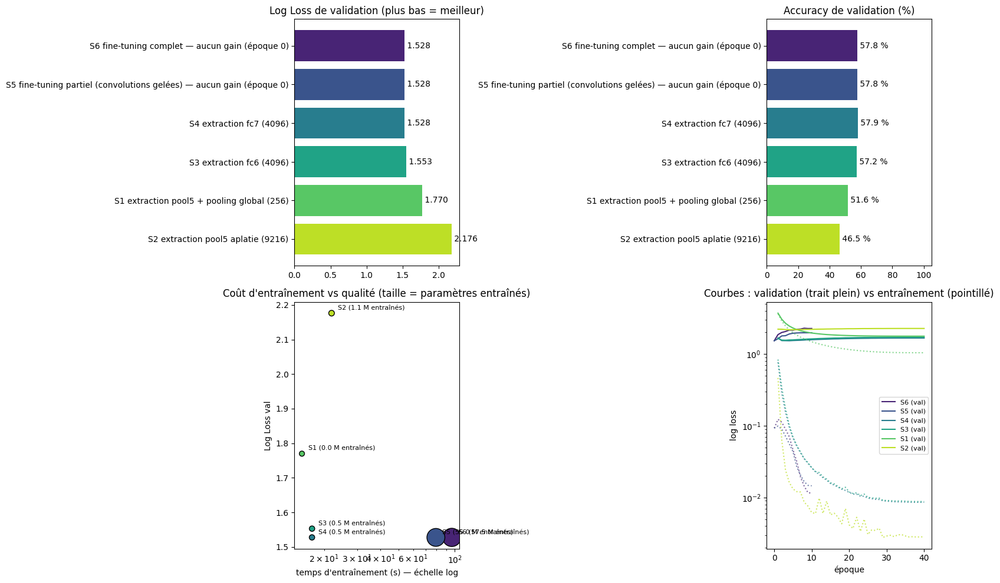

,Code,Stratégie,Log Loss val,Accuracy val,Confiance moyenne,ECE,rang Log Loss,rang Accuracy,sur-confiance (conf. − acc.)
0,S6,fine-tuning complet — aucun gain (époque 0),1.5279,0.5785,0.6284,0.0501,1,2,0.0499
1,S5,fine-tuning partiel (convolutions gelées) — aucun gain (époque 0),1.5279,0.5785,0.6284,0.0501,1,2,0.0499
2,S4,extraction fc7 (4096),1.5279,0.5790,0.6284,0.0507,3,1,0.0494
3,S3,extraction fc6 (4096),1.5532,0.5716,0.6244,0.0590,4,4,0.0528
4,S1,extraction pool5 + pooling global (256),1.7700,0.5164,0.4653,0.0515,5,5,-0.0511
5,S2,extraction pool5 aplatie (9216),2.1761,0.4650,0.6098,0.1447,6,6,0.1447


Classements Log Loss et Accuracy identiques : False


In [24]:
order = bench["Code"].tolist()
lbl = [f"{c} {d}" for c, d in zip(bench["Code"], bench["Stratégie"])]
colors = plt.cm.viridis(np.linspace(0.1, 0.9, len(order)))
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

ax = axes[0, 0]
ax.barh(lbl[::-1], bench["Log Loss val"][::-1], color=colors[::-1])
for i, v in enumerate(bench["Log Loss val"][::-1]): ax.text(v, i, f" {v:.3f}", va="center")
ax.set_title("Log Loss de validation (plus bas = meilleur)")

ax = axes[0, 1]
ax.barh(lbl[::-1], bench["Accuracy val"][::-1] * 100, color=colors[::-1])
for i, v in enumerate(bench["Accuracy val"][::-1] * 100): ax.text(v, i, f" {v:.1f} %", va="center")
ax.set_title("Accuracy de validation (%)"); ax.set_xlim(0, 105)

ax = axes[1, 0]
ax.scatter(bench["Temps entraînement (s)"], bench["Log Loss val"], s=bench["Paramètres entraînés (M)"] * 8 + 40,
           c=colors, edgecolor="k")
for _, r in bench.iterrows():
    ax.annotate(f"{r['Code']} ({r['Paramètres entraînés (M)']:.1f} M entraînés)", (r["Temps entraînement (s)"], r["Log Loss val"]),
                textcoords="offset points", xytext=(8, 4), fontsize=8)
ax.set_xscale("log"); ax.set_xlabel("temps d'entraînement (s) — échelle log"); ax.set_ylabel("Log Loss val")
ax.set_title("Coût d'entraînement vs qualité (taille = paramètres entraînés)")

ax = axes[1, 1]
for c, col in zip(order, colors):
    ax.plot(HISTS[c]["epoch"], HISTS[c]["val_loss"], color=col, label=f"{c} (val)")
    ax.plot(HISTS[c]["epoch"], HISTS[c]["train_loss"], color=col, ls=":", alpha=0.7)
ax.set_xlabel("époque"); ax.set_ylabel("log loss"); ax.set_yscale("log")
ax.set_title("Courbes : validation (trait plein) vs entraînement (pointillé)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "benchmark_strategies.png"), dpi=130); plt.show()

rk = bench[["Code", "Stratégie", "Log Loss val", "Accuracy val", "Confiance moyenne", "ECE"]].copy()
rk["rang Log Loss"] = rk["Log Loss val"].rank().astype(int)
rk["rang Accuracy"] = rk["Accuracy val"].rank(ascending=False).astype(int)
rk["sur-confiance (conf. − acc.)"] = rk["Confiance moyenne"] - rk["Accuracy val"]
display(rk)
print("Classements Log Loss et Accuracy identiques :", (rk["rang Log Loss"] == rk["rang Accuracy"]).all())

### Analyse du benchmark des stratégies

- **Quelle couche transférer ?** `fc7` (S4 : log loss ≈ 1,528, accuracy ≈ 57,9 %) et `fc6` (S3 : ≈ 1,553, 57,2 %) sont nettement meilleures que `pool5`. Les races de chiens font partie des 1 000 classes d'ImageNet, donc les couches hautes, spécialisées pour ces classes, sont utiles.
- **`pool5` aplatie (S2, 9 216 dim.) est la pire** (≈ 2,176, 46,5 %) alors qu'elle contient le plus d'information : un classifieur linéaire sur 9 216 dimensions avec ~68 images par race **sur-apprend** très vite (meilleure époque : 4), et chaque dimension correspond à une *position* précise dans l'image, ce qui n'est pas invariant au cadrage. Le **pooling global** (S1, 256 dim., ≈ 1,770) supprime ce problème mais perd l'information de disposition.
- **Fine-tuning (S5, S6) : aucun gain.** L'époque 0 (la tête S4 seule) reste la meilleure : dès la 1re époque, la loss d'entraînement tombe à ≈ 0,10 tandis que celle de validation **monte** (1,53 → 1,63 → 1,78…). Diagnostic : (1) la tête d'initialisation S4 a déjà presque « appris par cœur » le train, il ne reste quasiment pas de signal d'apprentissage ; (2) les ~55 M de paramètres de `fc6`/`fc7` mémorisent 8 177 images en une époque avec un taux de 1e-4. C'est une **tentative ratée mais expliquée** ; elle est corrigée en section 11 bis (fine-tuning régularisé).
- **Accuracy vs log loss** : les classements ne sont pas identiques (cellule précédente) ; un modèle peut gagner en accuracy et perdre en log loss s'il est plus sur-confiant (colonne ECE).
- **Coût** : les têtes S1–S4 s'entraînent en quelques secondes ; un fine-tuning coûte plusieurs minutes.

# 10 bis. Soumission n°1 (sécurité)

Meilleure stratégie du benchmark, telle quelle. `write_submission` vérifie automatiquement la conformité : colonnes et ordre identiques à `sample_submission.csv`, mêmes ids, 120 probabilités de somme 1, aucune valeur manquante. Les probabilités sont bornées à 1e-7 puis renormalisées.
**Soumettre** : télécharger le fichier puis *Late Submission* sur Kaggle (un fichier zippé est accepté s'il est trop gros, voir la cellule de compression en fin de notebook).

In [25]:
def write_submission(probs, fname, download=False):
    probs = np.clip(probs, 1e-7, 1.0)
    probs = probs / probs.sum(1, keepdims=True)
    sub = pd.DataFrame(probs, columns=BREEDS)
    sub.insert(0, "id", test_ids)
    assert list(sub.columns) == list(sample.columns)
    assert len(sub) == len(sample) and (sub["id"].values == sample["id"].values).all()
    assert np.allclose(sub[BREEDS].sum(1), 1.0, atol=1e-6) and not sub.isna().any().any()
    out = os.path.join(SUB_DIR, fname)
    sub.to_csv(out, index=False)
    print(f"OK : {out} — {sub.shape[0]} lignes x {sub.shape[1]} colonnes, chaque ligne somme à 1")
    if download and IN_COLAB:
        from google.colab import files
        files.download(out)
    return sub

# Un fine-tuning qui a retenu l'époque 0 est en réalité la tête S4 : on ne le présente pas comme « meilleure stratégie »
valid = bench[~(bench["Code"].isin(["S5", "S6"]) & (bench["Époque retenue"] == 0))].reset_index(drop=True)
best_strat = valid.iloc[0]["Code"]
print("Meilleure stratégie du benchmark :", best_strat, "—", valid.iloc[0]["Stratégie"])
sub1 = write_submission(softmax(TEST_BENCH[best_strat], 1), "submission_1_best_strategy.csv", download=True)

Meilleure stratégie du benchmark : S4 — extraction fc7 (4096)
OK : /content/drive/MyDrive/dog_breed_arena_alexnet/submissions/submission_1_best_strategy.csv — 10357 lignes x 121 colonnes, chaque ligne somme à 1


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# 11. Démarche d'optimisation

Deux pistes sont optimisées en parallèle puis combinées. **Chaque essai est mesuré sur la même validation** et consigné dans le journal `EXP`, qu'il fonctionne ou non (Δ = écart avec le meilleur résultat retenu de la même piste).

**Piste A — extraction de features (rapide)**

| Étape | Idée | Pourquoi |
|---|---|---|
| A1 | miroir à l'entraînement + TTA miroir | double les exemples ; prédiction plus stable |
| A2 | régularisation (dropout × weight decay) | tête moins sur-apprise et moins sur-confiante |
| A3 | **résolution d'entrée 288 / 352 px** | conv1 (11×11, pas de 4) écrase les détails fins à 224 px |
| A4 | calibration par température | corrige la sur/sous-confiance sans changer l'accuracy |

**Piste B — fine-tuning**

| Étape | Idée | Pourquoi |
|---|---|---|
| B1 | TTA miroir | moyenne image + miroir |
| B2 | TTA 10 crops | méthode d'évaluation du papier AlexNet (centre + 4 coins, × miroir) |
| B3 | TTA 12 vues | image entière + miroir + 10 crops |
| B4 | calibration par température | idem A4 |
| B5 | fine-tuning à la meilleure résolution de A3 | les gains de résolution se transfèrent-ils ? |

**C — ensemble A + B** : les deux pistes font-elles les mêmes erreurs ?

*Honnêteté* : températures et poids de l'ensemble sont mesurés en **validation croisée à 2 plis à l'intérieur de la validation**, pour ne pas évaluer un réglage sur les données qui l'ont choisi.

In [26]:
EXP, CUR = [], {}
def log_exp(branch, step, desc, ll, ac, keep=None):
    prev = CUR.get(branch)
    delta = None if prev is None else ll - prev
    keep = (delta is None or delta < 0) if keep is None else keep
    EXP.append({"piste": branch, "étape": step, "description": desc, "Log Loss val": ll, "Accuracy val": ac,
                "Δ vs meilleur précédent": delta, "retenu": keep})
    print(f"[{step}] {desc} → logloss {ll:.4f} | acc {ac:.4f}" + ("" if delta is None else f" | Δ {delta:+.4f}")
          + ("  retenu" if keep else "  NON retenu"))
    if keep:
        CUR[branch] = ll

def fit_temperature(logits, y):
    r = minimize_scalar(lambda t: nll(logits, y, np.exp(t)), bounds=(-2.5, 2.5), method="bounded")
    return float(np.exp(r.x))

def crossfit_temperature(logits, y, seed=SEED):
    """T apprise sur une moitié de la validation, évaluée sur l'autre (et inversement)."""
    out = np.zeros(len(y))
    for a, b in StratifiedKFold(n_splits=2, shuffle=True, random_state=seed).split(logits, y):
        T = fit_temperature(logits[a], y[a])
        out[b] = -log_softmax(logits[b] / T, 1)[np.arange(len(b)), y[b]]
    return float(out.mean()), fit_temperature(logits, y)

def fit_eval(layer, res, cfg, flip_aug=True, tta=True, idx=None):
    f, ff = load_feats(layer, res)
    idx = tr_idx if idx is None else idx
    Xtr, ytr = np.asarray(f[idx]), y_all[idx]
    if flip_aug:
        Xtr, ytr = np.concatenate([Xtr, np.asarray(ff[idx])]), np.concatenate([ytr, ytr])
    head, hist, ep = train_head(Xtr, ytr, f[va_idx], y_va, **cfg)
    lv = predict_logits(head, f[va_idx])
    if tta:
        lv = (lv + predict_logits(head, ff[va_idx])) / 2
    return head, lv, ep

# ---------------- Piste A ----------------
ext_codes = ["S1", "S2", "S3", "S4"]
A0 = min(ext_codes, key=lambda c: nll(VAL_BENCH[c], y_va))
A_LAYER = STRATS[A0][1]
log_exp("A", "A0", f"benchmark {A0} ({A_LAYER})", nll(VAL_BENCH[A0], y_va), acc(VAL_BENCH[A0], y_va))
_, lv, _ = fit_eval(A_LAYER, NATIVE_RES, HEAD_CFG)
log_exp("A", "A1", "+ miroir à l'entraînement + TTA miroir", nll(lv, y_va), acc(lv, y_va))
A_FLIP = EXP[-1]["retenu"]

[A0] benchmark S4 (fc7) → logloss 1.5279 | acc 0.5790  retenu
[A1] + miroir à l'entraînement + TTA miroir → logloss 1.5036 | acc 0.5897 | Δ -0.0243  retenu


,dropout,wd,logloss,acc,époque
0,0.3,0.5000,1.4878,0.5985,2
1,0.5,0.5000,1.4898,0.5892,2
2,0.3,0.1000,1.4909,0.5976,2
3,0.3,0.0001,1.4919,0.5976,2
4,0.5,0.1000,1.4923,0.5883,2
5,0.5,0.0001,1.4931,0.5883,2
6,0.0,0.5000,1.4969,0.5858,2
7,0.0,0.1000,1.5021,0.5878,2
8,0.0,0.0001,1.5036,0.5897,2


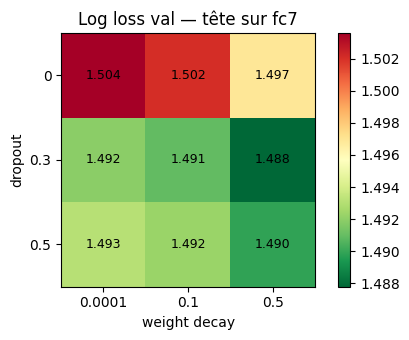

[A2] régularisation dropout=0.3, wd=0.5 → logloss 1.4878 | acc 0.5985 | Δ -0.0158  retenu


In [27]:
# A2 : régularisation — grille dropout x weight decay
grid = []
for dp in [0.0, 0.3, 0.5]:
    for wd in [1e-4, 1e-1, 5e-1]:
        cfg = {**HEAD_CFG, "dropout": dp, "wd": wd}
        _, lv, ep = fit_eval(A_LAYER, NATIVE_RES, cfg, flip_aug=A_FLIP, tta=A_FLIP)
        grid.append({"dropout": dp, "wd": wd, "logloss": nll(lv, y_va), "acc": acc(lv, y_va), "époque": ep})
grid = pd.DataFrame(grid).sort_values("logloss").reset_index(drop=True)
display(grid)

piv = grid.pivot(index="dropout", columns="wd", values="logloss")
fig, ax = plt.subplots(figsize=(5, 3.5))
im = ax.imshow(piv.values, cmap="RdYlGn_r")
ax.set_xticks(range(len(piv.columns)), [f"{c:g}" for c in piv.columns]); ax.set_xlabel("weight decay")
ax.set_yticks(range(len(piv.index)), [f"{c:g}" for c in piv.index]); ax.set_ylabel("dropout")
for i in range(piv.shape[0]):
    for j in range(piv.shape[1]):
        ax.text(j, i, f"{piv.values[i, j]:.3f}", ha="center", va="center", fontsize=9)
ax.set_title(f"Log loss val — tête sur {A_LAYER}"); plt.colorbar(im); plt.tight_layout(); plt.show()

A_CFG = {**HEAD_CFG, "dropout": float(grid.loc[0, "dropout"]), "wd": float(grid.loc[0, "wd"])}
log_exp("A", "A2", f"régularisation dropout={A_CFG['dropout']}, wd={A_CFG['wd']}", grid.loc[0, "logloss"], grid.loc[0, "acc"])
if not EXP[-1]["retenu"]:
    A_CFG = dict(HEAD_CFG)

features AlexNet 288 px:   0%|          | 0/81 [00:00<?, ?it/s]

features AlexNet 352 px:   0%|          | 0/81 [00:00<?, ?it/s]

résolution,224,288,352
couche,,,
fc6,1.5131,1.4301,1.4229
fc7,1.4878,1.4540,1.4299
pool5_gap,1.7379,1.6638,1.6753


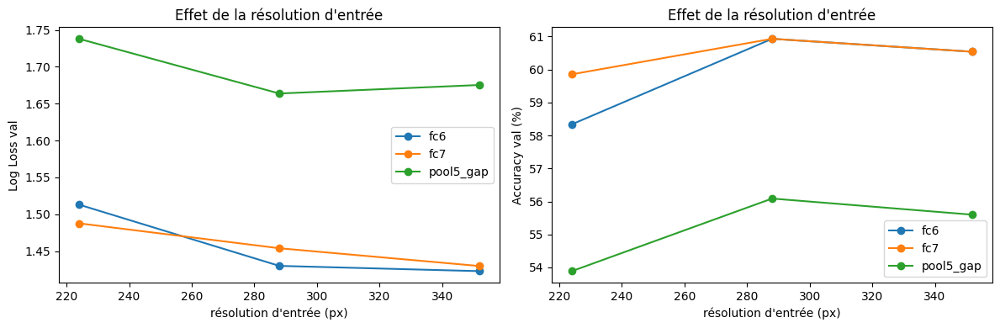

[A3] résolution 352 px, couche fc6 → logloss 1.4229 | acc 0.6054 | Δ -0.0648  retenu


In [28]:
# A3 : étude de résolution — le pas de 4 du filtre 11×11 limite-t-il AlexNet ?
for r in RES_LIST:
    EXTRACT_META[r] = extract(r)
res_rows = []
for r in RES_LIST:
    for layer in ["pool5_gap", "fc6", "fc7"]:
        _, lv, ep = fit_eval(layer, r, A_CFG, flip_aug=A_FLIP, tta=A_FLIP)
        res_rows.append({"résolution": r, "couche": layer, "logloss": nll(lv, y_va), "acc": acc(lv, y_va)})
res_df = pd.DataFrame(res_rows)
display(res_df.pivot(index="couche", columns="résolution", values="logloss").style.format("{:.4f}")
              .background_gradient(axis=None, cmap="RdYlGn_r"))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for layer, g in res_df.groupby("couche"):
    axes[0].plot(g["résolution"], g["logloss"], "o-", label=layer)
    axes[1].plot(g["résolution"], g["acc"] * 100, "o-", label=layer)
axes[0].set(xlabel="résolution d'entrée (px)", ylabel="Log Loss val", title="Effet de la résolution d'entrée")
axes[1].set(xlabel="résolution d'entrée (px)", ylabel="Accuracy val (%)", title="Effet de la résolution d'entrée")
axes[0].legend(); axes[1].legend()
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "resolution.png"), dpi=130); plt.show()

bestA = res_df.loc[res_df["logloss"].idxmin()]
A_LAYER, A_RES = bestA["couche"], int(bestA["résolution"])
if A_RES == NATIVE_RES and A_LAYER == STRATS[A0][1]:
    log_exp("A", "A3", f"résolution : 224 px reste la meilleure ({A_LAYER})", bestA["logloss"], bestA["acc"], keep=False)
else:
    log_exp("A", "A3", f"résolution {A_RES} px, couche {A_LAYER}", bestA["logloss"], bestA["acc"])
    if not EXP[-1]["retenu"]:
        A_LAYER, A_RES = STRATS[A0][1], NATIVE_RES

[A4] + température T=1.06 (validation croisée) → logloss 1.4232 | acc 0.6054 | Δ +0.0003  NON retenu
Piste A finale : {'layer': 'fc6', 'res': 352, 'cfg': {'epochs': 40, 'lr': 0.001, 'wd': 0.5, 'dropout': 0.3, 'bs': 256, 'label_smoothing': 0.0}, 'flip': True, 'T': 1.0, 'epoch': 2}


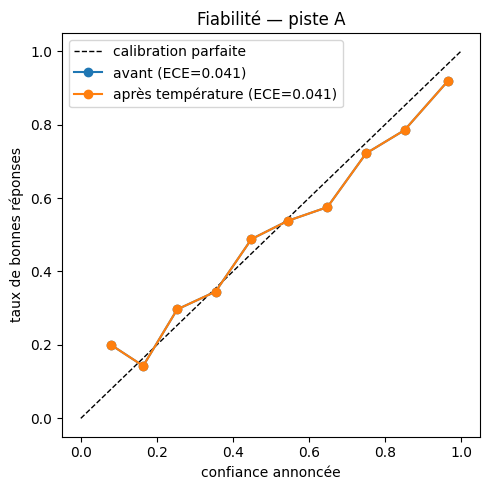

In [29]:
# A4 : calibration par température
A_HEAD, lvA, A_EPOCH = fit_eval(A_LAYER, A_RES, A_CFG, flip_aug=A_FLIP, tta=A_FLIP)
llA_T, A_T = crossfit_temperature(lvA, y_va)
log_exp("A", "A4", f"+ température T={A_T:.2f} (validation croisée)", llA_T, acc(lvA, y_va))
if not EXP[-1]["retenu"]:
    A_T = 1.0
A_FINAL = {"layer": A_LAYER, "res": A_RES, "cfg": A_CFG, "flip": A_FLIP, "T": A_T, "epoch": int(A_EPOCH)}
P_VAL_A = softmax(lvA / A_T, 1)
print("Piste A finale :", A_FINAL)

def reliability(ax, logits, y, label, n_bins=10):
    p = softmax(logits, 1); conf = p.max(1); ok = p.argmax(1) == y
    edges = np.linspace(0, 1, n_bins + 1); xs, ys = [], []
    for lo, hi in zip(edges[:-1], edges[1:]):
        mk = (conf > lo) & (conf <= hi)
        if mk.sum() > 5:
            xs.append(conf[mk].mean()); ys.append(ok[mk].mean())
    ax.plot(xs, ys, "o-", label=f"{label} (ECE={ece(logits, y):.3f})")
fig, ax = plt.subplots(figsize=(5, 5))
ax.plot([0, 1], [0, 1], "k--", lw=1, label="calibration parfaite")
reliability(ax, lvA, y_va, "avant")
reliability(ax, lvA / A_T, y_va, "après température")
ax.set(xlabel="confiance annoncée", ylabel="taux de bonnes réponses", title="Fiabilité — piste A")
ax.legend(); plt.tight_layout(); plt.show()

In [30]:
# ---------------- Piste B : fine-tuning ----------------
B0 = min(["S5", "S6"], key=lambda c: nll(VAL_BENCH[c], y_va))
B_INFO, B_ARRS = FT_RUNS[B0]
B_RES = NATIVE_RES
log_exp("B", "B0", f"benchmark {B0} ({'fine-tuning complet' if B_INFO['train_convs'] else 'fine-tuning partiel'})",
        nll(VAL_BENCH[B0], y_va), acc(VAL_BENCH[B0], y_va))

TTA_SETS = {"aucune": ["full"], "miroir": ["full", "full_flip"], "10 crops": CROP_VIEWS, "12 vues": ALL_VIEWS}
def tta(arrs, prefix, views):
    return np.mean([arrs[f"{prefix}_{v}"] for v in views], axis=0)

tta_scores = {"aucune": nll(tta(B_ARRS, "val", TTA_SETS["aucune"]), y_va)}
for step, name in [("B1", "miroir"), ("B2", "10 crops"), ("B3", "12 vues")]:
    lv = tta(B_ARRS, "val", TTA_SETS[name])
    tta_scores[name] = nll(lv, y_va)
    log_exp("B", step, f"TTA {name}", tta_scores[name], acc(lv, y_va))
B_TTA = min(tta_scores, key=tta_scores.get)
lvB = tta(B_ARRS, "val", TTA_SETS[B_TTA])
llB_T, B_T = crossfit_temperature(lvB, y_va)
log_exp("B", "B4", f"+ température T={B_T:.2f} sur TTA « {B_TTA} »", llB_T, acc(lvB, y_va))
if not EXP[-1]["retenu"]:
    B_T = 1.0

[B0] benchmark S5 (fine-tuning partiel) → logloss 1.5279 | acc 0.5785  retenu
[B1] TTA miroir → logloss 1.4844 | acc 0.5936 | Δ -0.0435  retenu
[B2] TTA 10 crops → logloss 1.4022 | acc 0.6073 | Δ -0.0822  retenu
[B3] TTA 12 vues → logloss 1.3970 | acc 0.6132 | Δ -0.0052  retenu
[B4] + température T=1.03 sur TTA « 12 vues » → logloss 1.3960 | acc 0.6132 | Δ -0.0009  retenu


In [31]:
# B5 : fine-tuning à plus haute résolution (≈ (res/224)² fois plus long). Mettre False si vous êtes en retard.
RUN_FT_HIRES = True
B_STRAT = B0
if RUN_FT_HIRES and A_RES != NATIVE_RES:
    head_r, _ = lp_head(A_RES, tr_idx)
    info_hr, arrs_hr = finetune(f"{B0}_r{A_RES}", FT_CFG, tr_idx, head_r, train_convs=B_INFO["train_convs"], res=A_RES)
    lv_hr = tta(arrs_hr, "val", TTA_SETS[B_TTA])
    ll_hr, T_hr = crossfit_temperature(lv_hr, y_va)
    log_exp("B", "B5", f"fine-tuning à {A_RES} px (TTA « {B_TTA} » + température {T_hr:.2f})", ll_hr, acc(lv_hr, y_va))
    if EXP[-1]["retenu"]:
        B_INFO, B_ARRS, B_RES, B_T, lvB = info_hr, arrs_hr, A_RES, T_hr, lv_hr
else:
    print("B5 non exécuté (résolution optimale = 224 px ou RUN_FT_HIRES = False)")

B_FINAL = {"strategy": B_STRAT, "train_convs": B_INFO["train_convs"], "res": B_RES, "tta": B_TTA, "T": B_T,
           "epoch": int(B_INFO["best_epoch"])}
P_VAL_B = softmax(lvB / B_T, 1)
print("Piste B finale :", B_FINAL)

[S5_r352] résultats rechargés depuis Drive
[B5] fine-tuning à 352 px (TTA « 12 vues » + température 0.99) → logloss 1.4188 | acc 0.5990 | Δ +0.0227  NON retenu
Piste B finale : {'strategy': 'S5', 'train_convs': False, 'res': 224, 'tta': '12 vues', 'T': 1.034248623959562, 'epoch': 0}


# 11 bis. Améliorations avancées (diagnostic → solution)

**Diagnostic de nos résultats** : toutes les têtes logistiques ont une log loss d'**entraînement proche de 0,1** contre **≈ 1,4–1,5 en validation**, et le fine-tuning sur-apprend dès la 1re époque. Le facteur limitant n'est donc pas seulement la qualité des features : c'est la **mémorisation** des ~68 images par race. Trois remèdes, chacun mesuré :

| Étape | Technique | Pourquoi |
|---|---|---|
| A5 | **Entraînement multi-vues** : pour chaque image d'entraînement, les features de 12 vues (image entière, miroir, 10 crops) ; même moyenne des 12 vues au test | 12× plus d'exemples **variés** (augmentation de données dans l'espace des features) → la tête ne peut plus mémoriser ; entraînement et test voient les mêmes vues |
| B6 | **Fine-tuning régularisé** : fc8 aléatoire (pas de tête déjà sur-apprise), taux bas (3e-5) pour les couches pré-entraînées, recadrages forts (10–100 % de la surface), **mixup**, 288 px | le mixup mélange deux images et leurs étiquettes : le réseau ne peut plus apprendre une réponse « par cœur » et ses probabilités deviennent moins extrêmes, ce que récompense la log loss |
| C1 | **Ensemble pondéré** de tous les modèles (poids optimisés sur la validation) | des modèles à résolutions, couches et entraînements différents font des erreurs en partie différentes |

Coût : extraction 12 vues à 288 et 352 px ≈ 3-4 min (≈ 8 Go sur le disque local), têtes ≈ 5 min, fine-tuning régularisé ≈ 8-12 min.

In [32]:
# A5 : extraction multi-vues (12 vues par image) pour fc6 et fc7, à 288 et 352 px
MV_VIEWS = ALL_VIEWS
MV_RES = [288, 352]
MV_LAYERS = ["fc6", "fc7"]

def mv_path(layer, res):
    return os.path.join(FEAT_DIR, f"mv_{layer}_r{res}.npy")

@torch.no_grad()
def extract_mv(res, layers=MV_LAYERS, bs=128):
    done = os.path.join(FEAT_DIR, f"mv_r{res}.json")
    if os.path.exists(done):
        return json.load(open(done))
    m = load_alexnet().eval().to(DEVICE).to(memory_format=torch.channels_last)
    N, S = len(cache), round(res * 256 / 224)
    mms = {l: np.lib.format.open_memmap(mv_path(l, res), mode="w+", dtype=np.float16,
                                        shape=(len(MV_VIEWS), N, LAYER_DIM[l])) for l in layers}
    if DEVICE == "cuda": torch.cuda.synchronize()
    t0 = time.time()
    for i in tqdm(range(0, N, bs), desc=f"features 12 vues {res} px"):
        x01 = to01(torch.from_numpy(np.ascontiguousarray(cache[i:i + bs])))
        full, big = resize(x01, res), resize(x01, S)
        for vi, v in enumerate(MV_VIEWS):
            with torch.autocast("cuda", dtype=torch.float16, enabled=DEVICE == "cuda"):
                o = alexnet_layers(m, normalize(make_view(full, big, v, res)), layers)
            for l in layers:
                mms[l][vi, i:i + bs] = o[l].float().cpu().numpy()
    if DEVICE == "cuda": torch.cuda.synchronize()
    meta = {"res": res, "t_extract_s": time.time() - t0}
    for a in mms.values():
        a.flush()
    del mms, m
    json.dump(meta, open(done, "w"))
    return meta

for r in MV_RES:
    print(f"{r} px : extraction 12 vues en {extract_mv(r)['t_extract_s']:.0f} s")

def mv_open(layer, res):
    return np.load(mv_path(layer, res), mmap_mode="r")            # (12 vues, N images, D)

def mv_fit(layer, res, cfg, idx=None, stop_at=None):
    idx = tr_idx if idx is None else idx
    mv = mv_open(layer, res)
    X = np.asarray(mv[:, idx]).reshape(-1, mv.shape[2])           # 12 x n exemples
    Y = np.tile(y_all[idx], mv.shape[0])
    if stop_at is None:
        return train_head(X, Y, yva=y_va, Xva_views=[mv[v, va_idx] for v in range(mv.shape[0])], **cfg)
    return train_head(X, Y, stop_at=stop_at, **cfg)

def mv_predict(head, layer, res, idx):
    mv = mv_open(layer, res)
    return np.mean([predict_logits(head, mv[v, idx]) for v in range(mv.shape[0])], axis=0)

features 12 vues 288 px:   0%|          | 0/161 [00:00<?, ?it/s]

288 px : extraction 12 vues en 110 s


features 12 vues 352 px:   0%|          | 0/161 [00:00<?, ?it/s]

352 px : extraction 12 vues en 138 s


In [33]:
# A5 : réglage de la régularisation sur une configuration, puis application à fc6 / fc7 x 288 / 352 px
g_layer = A_LAYER if A_LAYER in MV_LAYERS else "fc6"          # meilleure couche / résolution de A3 si disponible en 12 vues
g_res = A_RES if A_RES in MV_RES else MV_RES[-1]
MV_GRID = [dict(dropout=0.3, wd=0.5), dict(dropout=0.5, wd=0.5), dict(dropout=0.0, wd=1e-4)]
grid_mv = []
for g in MV_GRID:
    cfg = {**HEAD_CFG, "epochs": 25, **g}
    head, _, ep = mv_fit(g_layer, g_res, cfg)
    lv = mv_predict(head, g_layer, g_res, va_idx)
    grid_mv.append({**g, "logloss": nll(lv, y_va), "acc": acc(lv, y_va), "époque": ep})
grid_mv = pd.DataFrame(grid_mv).sort_values("logloss").reset_index(drop=True)
print(f"Réglage sur {g_layer} {g_res} px (12 vues) :"); display(grid_mv)
MV_CFG = {**HEAD_CFG, "epochs": 25, "dropout": float(grid_mv.loc[0, "dropout"]), "wd": float(grid_mv.loc[0, "wd"])}

MV_HEADS, MV_VAL, MV_EP, mv_rows = {}, {}, {}, []
for r in MV_RES:
    for l in MV_LAYERS:
        t0 = time.time()
        head, hist, ep = mv_fit(l, r, MV_CFG)
        lv = mv_predict(head, l, r, va_idx)
        MV_HEADS[(l, r)], MV_VAL[(l, r)], MV_EP[(l, r)] = head, lv, ep
        mv_rows.append({"couche": l, "résolution": r, "logloss": nll(lv, y_va), "acc": acc(lv, y_va),
                        "époque": ep, "temps (s)": time.time() - t0})
        log_exp("A", "A5", f"multi-vues (12 vues) {l} {r} px", nll(lv, y_va), acc(lv, y_va))
mv_df = pd.DataFrame(mv_rows); display(mv_df)

Réglage sur fc6 352 px (12 vues) :


,dropout,wd,logloss,acc,époque
0,0.3,0.5000,1.4300,0.6147,1
1,0.5,0.5000,1.4348,0.6117,1
2,0.0,0.0001,1.4734,0.6059,1


[A5] multi-vues (12 vues) fc6 288 px → logloss 1.3975 | acc 0.6215 | Δ -0.0254  retenu
[A5] multi-vues (12 vues) fc7 288 px → logloss 1.3976 | acc 0.6259 | Δ +0.0000  NON retenu
[A5] multi-vues (12 vues) fc6 352 px → logloss 1.4300 | acc 0.6147 | Δ +0.0325  NON retenu
[A5] multi-vues (12 vues) fc7 352 px → logloss 1.4474 | acc 0.6020 | Δ +0.0498  NON retenu


,couche,résolution,logloss,acc,époque,temps (s)
0,fc6,288,1.3975,0.6215,1,21.9136
1,fc7,288,1.3976,0.6259,1,22.2356
2,fc6,352,1.4300,0.6147,1,18.0572
3,fc7,352,1.4474,0.6020,1,22.3296


[FT2_r288] résultats rechargés depuis Drive
Log loss du fine-tuning régularisé selon la TTA : {'aucune': 1.4886, 'miroir': 1.4738, '10 crops': 1.3786, '12 vues': 1.3821}
[B6] fine-tuning régularisé (mixup, crops forts, fc8 aléatoire, 288 px) + TTA « 10 crops » → logloss 1.3786 | acc 0.6259 | Δ -0.0174  retenu


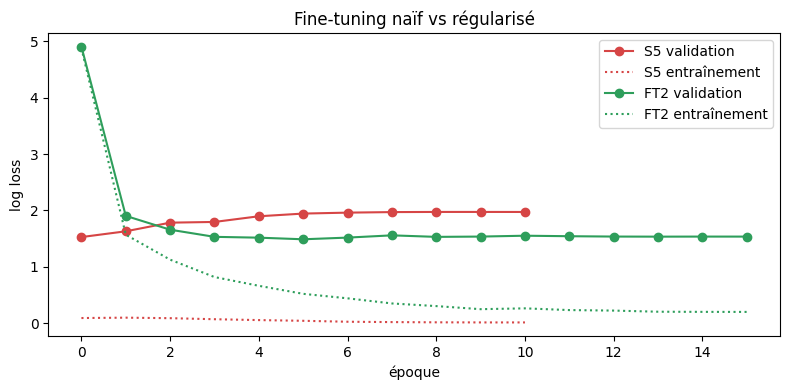

In [34]:
# B6 : fine-tuning régularisé (≈ 8-12 min sur T4). Mettre RUN_FT2 = False si vous manquez de temps.
FT_CFG2 = dict(epochs=15, bs=128, lr_conv=3e-5, lr_fc=3e-5, lr_head=1e-3, wd=5e-2, warmup=1,
               scale=(0.10, 1.0), ratio=(3 / 4, 4 / 3), jitter=0.3, dropout=0.5, mixup=0.2, head_init="random")
FT2_RES = 288
RUN_FT2 = True
FT_CFGS = {"FT_CFG": FT_CFG, "FT_CFG2": FT_CFG2}
if RUN_FT2:
    FT2_INFO, FT2_ARRS = finetune(f"FT2_r{FT2_RES}", FT_CFG2, tr_idx, None, train_convs=True, res=FT2_RES)
    HISTS["FT2"] = pd.DataFrame(FT2_INFO["hist"])
    tta2 = {k: nll(tta(FT2_ARRS, "val", v), y_va) for k, v in TTA_SETS.items()}
    FT2_TTA = min(tta2, key=tta2.get)
    lv2 = tta(FT2_ARRS, "val", TTA_SETS[FT2_TTA])
    print("Log loss du fine-tuning régularisé selon la TTA :", {k: round(v, 4) for k, v in tta2.items()})
    log_exp("B", "B6", f"fine-tuning régularisé (mixup, crops forts, fc8 aléatoire, {FT2_RES} px) + TTA « {FT2_TTA} »",
            nll(lv2, y_va), acc(lv2, y_va))

    fig, ax = plt.subplots(figsize=(8, 4))
    for name, col in [(B0, "#d64545"), ("FT2", "#2e9e5b")]:
        h = HISTS[name]
        ax.plot(h["epoch"], h["val_loss"], "-o", color=col, label=f"{name} validation")
        ax.plot(h["epoch"], h["train_loss"], ":", color=col, label=f"{name} entraînement")
    ax.set(xlabel="époque", ylabel="log loss", title="Fine-tuning naïf vs régularisé")
    ax.legend(); plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "finetuning_v2.png"), dpi=130); plt.show()

,modèle,Log Loss val (brute),"Log Loss val (température, val. croisée)",Accuracy val,T,poids dans l'ensemble
6,FT2 · fine-tuning régularisé 288 px (TTA 10 crops),1.3786,1.3761,0.6259,0.9346,0.2872
1,B · S5 224 px (TTA 12 vues),1.3970,1.3960,0.6132,1.0342,0.2154
0,A · tête fc6 352 px (1 vue),1.4229,1.4232,0.6054,1.0571,0.1416
3,MV · fc7 288 px (12 vues),1.3976,1.3669,0.6259,1.2018,0.1300
2,MV · fc6 288 px (12 vues),1.3975,1.3603,0.6215,1.2353,0.1224
4,MV · fc6 352 px (12 vues),1.4300,1.3914,0.6147,1.2370,0.1034
5,MV · fc7 352 px (12 vues),1.4474,1.4116,0.6020,1.2194,0.0000


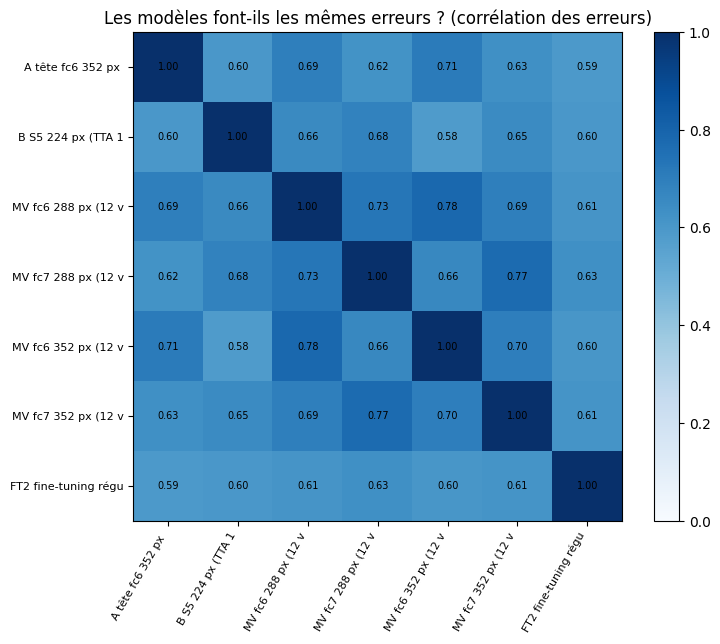

[C1] ensemble pondéré de 6 modèles (poids et températures en validation croisée) → logloss 1.2403 | acc 0.6528 | Δ -0.1199  retenu
Configuration finale :
  poids 0.14 — A · tête fc6 352 px (1 vue)
  poids 0.22 — B · S5 224 px (TTA 12 vues)
  poids 0.12 — MV · fc6 288 px (12 vues)
  poids 0.13 — MV · fc7 288 px (12 vues)
  poids 0.10 — MV · fc6 352 px (12 vues)
  poids 0.29 — FT2 · fine-tuning régularisé 288 px (TTA 10 crops)


In [35]:
# C1 : ensemble pondéré de tous les modèles candidats
from scipy.optimize import minimize
CANDS = {f"A · tête {A_FINAL['layer']} {A_FINAL['res']} px (1 vue)": ({"kind": "head", **A_FINAL}, lvA),
         f"B · {B_FINAL['strategy']} {B_FINAL['res']} px (TTA {B_FINAL['tta']})":
             ({"kind": "ft", "cfg_name": "FT_CFG", "head_init": "lp", **B_FINAL}, lvB)}
for (l, r), lv in MV_VAL.items():
    CANDS[f"MV · {l} {r} px (12 vues)"] = ({"kind": "mv", "layer": l, "res": r, "cfg": MV_CFG, "epoch": int(MV_EP[(l, r)])}, lv)
if RUN_FT2:
    CANDS[f"FT2 · fine-tuning régularisé {FT2_RES} px (TTA {FT2_TTA})"] = (
        {"kind": "ft", "cfg_name": "FT_CFG2", "head_init": "random", "strategy": "FT2", "train_convs": True,
         "res": FT2_RES, "tta": FT2_TTA, "epoch": int(FT2_INFO["best_epoch"])}, lv2)

names, PROBS, cand_rows = list(CANDS), {}, []
for n in names:
    spec, lv = CANDS[n]
    ll_cf, T = crossfit_temperature(lv, y_va)
    spec["T"] = T
    PROBS[n] = softmax(lv / T, 1)
    cand_rows.append({"modèle": n, "Log Loss val (brute)": nll(lv, y_va), "Log Loss val (température, val. croisée)": ll_cf,
                      "Accuracy val": acc(lv, y_va), "T": T})
cand_df = pd.DataFrame(cand_rows)

PY = np.stack([PROBS[n][np.arange(len(y_va)), y_va] for n in names])     # proba de la vraie race : (K modèles, n images)
def fit_weights(py):
    f = lambda z: -np.log(softmax(z) @ py + 1e-15).mean()
    return softmax(minimize(f, np.zeros(len(py)), method="L-BFGS-B").x)

out = np.zeros(len(y_va))
for a, b in StratifiedKFold(n_splits=2, shuffle=True, random_state=SEED).split(PY.T, y_va):
    out[b] = -np.log(fit_weights(PY[:, a]) @ PY[:, b] + 1e-15)          # poids appris sur une moitié, évalués sur l'autre
ll_ens = float(out.mean())
W = fit_weights(PY)
W = np.where(W >= 0.02, W, 0); W = W / W.sum()                         # on retire les modèles quasi inutiles
cand_df["poids dans l'ensemble"] = W
display(cand_df.sort_values("poids dans l'ensemble", ascending=False).style.format(precision=4)
        .background_gradient(subset=["Log Loss val (température, val. croisée)"], cmap="RdYlGn_r"))

E = np.stack([PROBS[n].argmax(1) != y_va for n in names]).astype(float)
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(np.corrcoef(E), cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(names)), [n.split(" · ")[0] + " " + n.split(" · ")[1][:16] for n in names], rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(names)), [n.split(" · ")[0] + " " + n.split(" · ")[1][:16] for n in names], fontsize=8)
for i in range(len(names)):
    for j in range(len(names)):
        ax.text(j, i, f"{np.corrcoef(E)[i, j]:.2f}", ha="center", va="center", fontsize=7)
ax.set_title("Les modèles font-ils les mêmes erreurs ? (corrélation des erreurs)"); plt.colorbar(im)
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "correlation_erreurs.png"), dpi=130); plt.show()

CUR["C"] = float(cand_df["Log Loss val (température, val. croisée)"].min())
P_ens = sum(w * PROBS[n] for n, w in zip(names, W))
log_exp("C", "C1", f"ensemble pondéré de {int((W > 0).sum())} modèles (poids et températures en validation croisée)",
        ll_ens, float((P_ens.argmax(1) == y_va).mean()))
if not EXP[-1]["retenu"]:                                               # sinon : le meilleur modèle seul
    W = np.zeros(len(names)); W[int(cand_df["Log Loss val (température, val. croisée)"].idxmin())] = 1.0
P_VAL_FINAL = sum(w * PROBS[n] for n, w in zip(names, W))

FINAL = {"members": [{"name": n, "w": float(w), **CANDS[n][0]} for n, w in zip(names, W) if w > 0]}
json.dump(FINAL, open(os.path.join(WORK_DIR, "final_config.json"), "w"), indent=1)
print("Configuration finale :")
for m in FINAL["members"]:
    print(f"  poids {m['w']:.2f} — {m['name']}")

,piste,étape,description,Log Loss val,Accuracy val,Δ vs meilleur précédent,retenu
0,A,A0,benchmark S4 (fc7),1.5279,0.5790,NaN,True
1,A,A1,+ miroir à l'entraînement + TTA miroir,1.5036,0.5897,-2.4276e-02,True
2,A,A2,"régularisation dropout=0.3, wd=0.5",1.4878,0.5985,-1.5831e-02,True
3,A,A3,"résolution 352 px, couche fc6",1.4229,0.6054,-6.4835e-02,True
4,A,A4,+ température T=1.06 (validation croisée),1.4232,0.6054,2.6460e-04,False
5,B,B0,benchmark S5 (fine-tuning partiel),1.5279,0.5785,NaN,True
6,B,B1,TTA miroir,1.4844,0.5936,-4.3451e-02,True
7,B,B2,TTA 10 crops,1.4022,0.6073,-8.2192e-02,True
8,B,B3,TTA 12 vues,1.3970,0.6132,-5.2412e-03,True
9,B,B4,+ température T=1.03 sur TTA « 12 vues »,1.3960,0.6132,-9.1929e-04,True


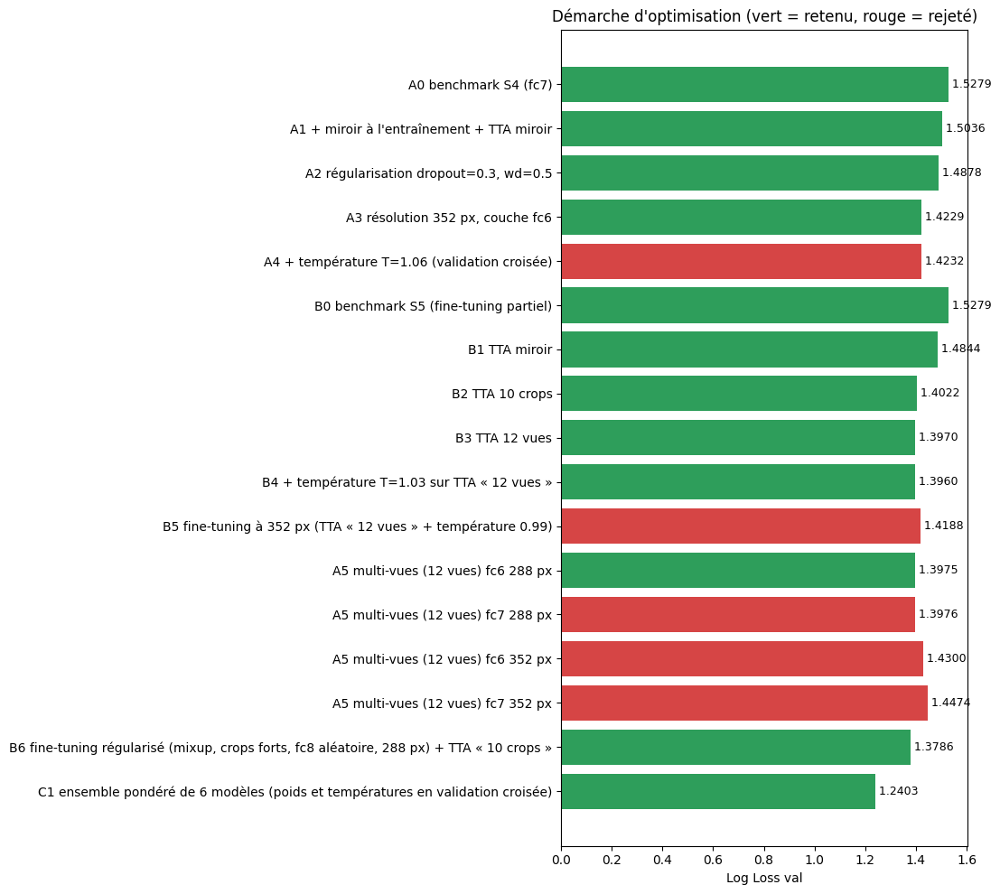

In [36]:
exp_df = pd.DataFrame(EXP)
exp_df.to_csv(os.path.join(WORK_DIR, "optimisation_log.csv"), index=False)
display(exp_df)

fig, ax = plt.subplots(figsize=(11, 0.5 * len(exp_df) + 1.5))
lab = [f"{r['étape']} {r['description']}" for _, r in exp_df.iterrows()]
ax.barh(lab[::-1], exp_df["Log Loss val"][::-1], color=["#2e9e5b" if k else "#d64545" for k in exp_df["retenu"][::-1]])
for i, v in enumerate(exp_df["Log Loss val"][::-1]): ax.text(v, i, f" {v:.4f}", va="center", fontsize=9)
ax.set_xlabel("Log Loss val"); ax.set_title("Démarche d'optimisation (vert = retenu, rouge = rejeté)")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "optimisation.png"), dpi=130); plt.show()

### Commentaire de l'optimisation

- **Miroir + TTA (A1, −0,024) et régularisation (A2, −0,016)** : gains modestes mais gratuits.
- **Résolution (A3, −0,065 : `fc6` à 352 px, log loss ≈ 1,423)** : confirme notre hypothèse. À 224 px, le premier filtre 11×11 de pas 4 écrase les détails fins ; en agrandissant l'image, chaque pas de 4 pixels couvre une plus petite portion du chien. À cette résolution, `fc6` (plus générique) dépasse `fc7`.
- **TTA 10 crops (B2, ≈ 1,484 → 1,402)** : la méthode d'évaluation du papier de 2012 apporte nettement plus que le seul miroir : plusieurs cadrages compensent un chien mal centré.
- **Température (A4, B4)** : quasi nulle ici (T ≈ 1) : les têtes étaient déjà bien calibrées — un résultat négatif qui a du sens.
- **Fine-tuning à 352 px (B5)** : rejeté, pour la même raison que S5/S6 (mémorisation immédiate).
- **Multi-vues (A5)** : gain de −0,025 à 288 px (log loss 1,3975 pour `fc6`) : donner 12 vues de chaque image à la tête réduit la mémorisation. À 352 px, aucun gain : les crops couvrent une zone plus petite de l'image d'origine et ajoutent du bruit plutôt que de la diversité.
- **Fine-tuning régularisé (B6)** : premier fine-tuning qui fonctionne (1,3786 avec TTA 10 crops, meilleur modèle seul ; 1,4886 sans TTA). Avec le mixup et une fc8 aléatoire, la loss d'entraînement reste à 0,52 à l'époque 5 (meilleure époque), contre 0,10 dès l'époque 1 pour le fine-tuning naïf : la mémorisation est maîtrisée (figure « naïf vs régularisé »).
- **Ensemble pondéré (C1)** : 1,2403 en validation croisée (−0,12 par rapport au meilleur modèle seul), le plus grand gain de toute la démarche. Le fine-tuning régularisé reçoit le poids le plus fort (0,29), car ses erreurs diffèrent le plus de celles des têtes gelées (matrice de corrélation des erreurs) ; les 5 autres modèles se partagent le reste (0,10 à 0,22).
- **Biais résiduel** : températures et poids sont choisis sur la validation mais **évalués en validation croisée** ; le score Kaggle reste le contrôle final.

# 12. Analyse des erreurs du modèle final (validation)

In [37]:
pred = P_VAL_FINAL.argmax(1)
cm = np.zeros((N_CLASSES, N_CLASSES), int)
np.add.at(cm, (y_va, pred), 1)
li = -np.log(P_VAL_FINAL[np.arange(len(y_va)), y_va] + 1e-15)
print(f"Modèle final — log loss val = {li.mean():.4f}, accuracy val = {(pred == y_va).mean():.4f}, "
      f"erreurs = {(pred != y_va).sum()} / {len(y_va)}")

pairs = []
for i in range(N_CLASSES):
    for j in range(i + 1, N_CLASSES):
        if cm[i, j] + cm[j, i] > 0:
            pairs.append({"race A": BREEDS[i], "race B": BREEDS[j], "A prédite B": cm[i, j], "B prédite A": cm[j, i],
                          "total": cm[i, j] + cm[j, i]})
pairs = pd.DataFrame(pairs).sort_values("total", ascending=False).reset_index(drop=True)
display(pairs.head(15))
top5 = np.sort(li)[::-1][: max(1, len(li) // 20)].sum() / li.sum()
print(f"Les 5 % d'images les plus mal prédites représentent {top5 * 100:.0f} % de la log loss totale.")

Modèle final — log loss val = 1.2331, accuracy val = 0.6528, erreurs = 710 / 2045


,race A,race B,A prédite B,B prédite A,total
0,malamute,siberian_husky,5,6,11
1,redbone,rhodesian_ridgeback,5,4,9
2,eskimo_dog,siberian_husky,4,4,8
3,norfolk_terrier,norwich_terrier,4,4,8
4,irish_wolfhound,scottish_deerhound,4,4,8
5,lhasa,shih-tzu,3,4,7
6,miniature_poodle,toy_poodle,5,2,7
7,collie,shetland_sheepdog,6,1,7
8,doberman,miniature_pinscher,6,1,7
9,lakeland_terrier,wire-haired_fox_terrier,3,3,6


Les 5 % d'images les plus mal prédites représentent 21 % de la log loss totale.


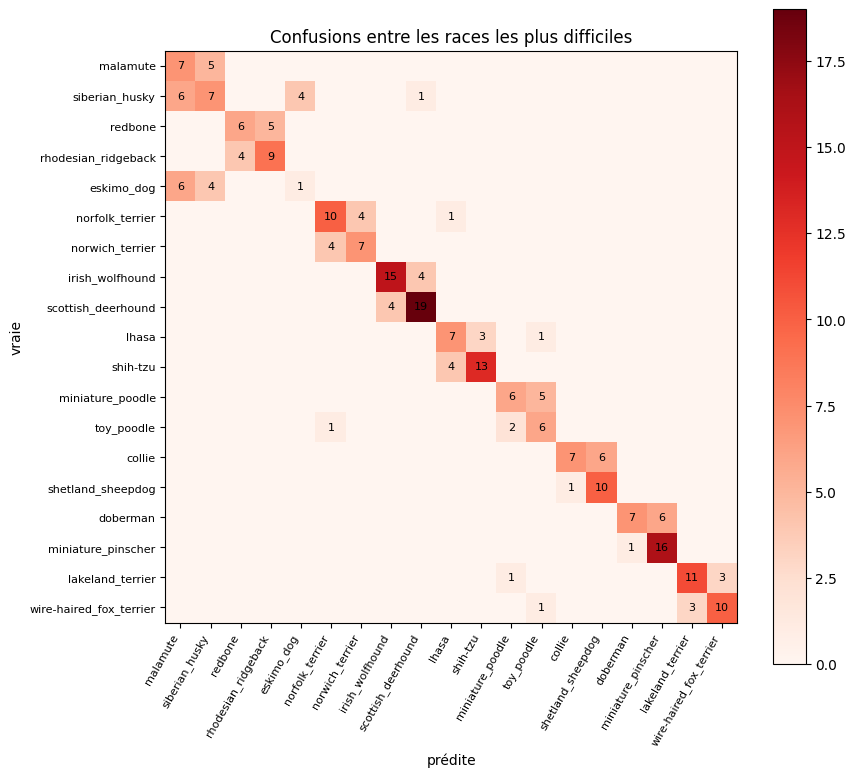

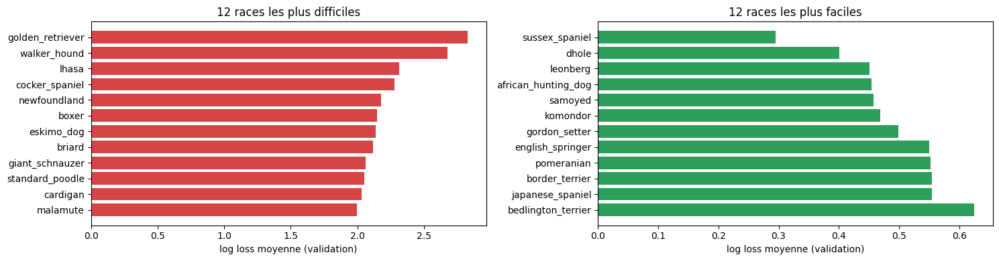

In [38]:
sub_breeds = list(dict.fromkeys(pairs.head(10)[["race A", "race B"]].values.ravel()))
ix = [BREED2IDX[b] for b in sub_breeds]
sub_cm = cm[np.ix_(ix, ix)]
fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(sub_cm, cmap="Reds")
ax.set_xticks(range(len(ix)), sub_breeds, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(ix)), sub_breeds, fontsize=8)
for i in range(len(ix)):
    for j in range(len(ix)):
        if sub_cm[i, j]:
            ax.text(j, i, sub_cm[i, j], ha="center", va="center", fontsize=8)
ax.set_xlabel("prédite"); ax.set_ylabel("vraie"); ax.set_title("Confusions entre les races les plus difficiles")
plt.colorbar(im); plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "confusions.png"), dpi=130); plt.show()

per_class = pd.DataFrame({"race": BREEDS,
                          "accuracy": [(pred[y_va == c] == c).mean() for c in range(N_CLASSES)],
                          "log loss moyenne": [li[y_va == c].mean() for c in range(N_CLASSES)]})
worst = per_class.sort_values("log loss moyenne", ascending=False).head(12)
best = per_class.sort_values("log loss moyenne").head(12)
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
axes[0].barh(worst["race"][::-1], worst["log loss moyenne"][::-1], color="#d64545"); axes[0].set_title("12 races les plus difficiles")
axes[1].barh(best["race"][::-1], best["log loss moyenne"][::-1], color="#2e9e5b"); axes[1].set_title("12 races les plus faciles")
for a in axes: a.set_xlabel("log loss moyenne (validation)")
plt.tight_layout(); plt.show()

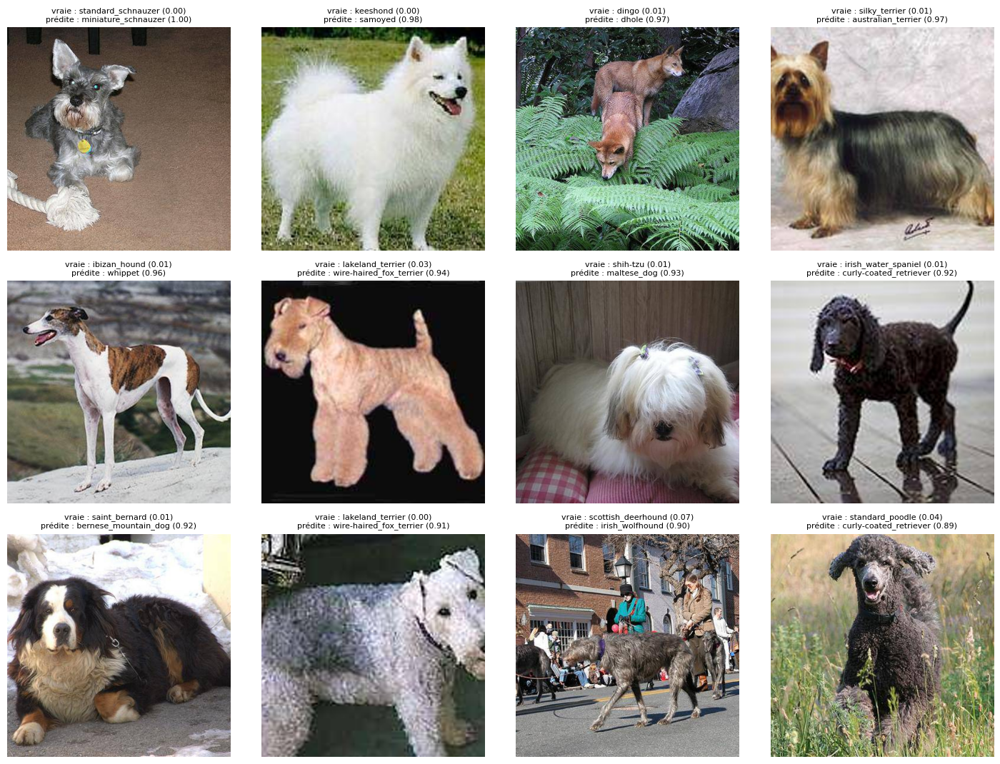

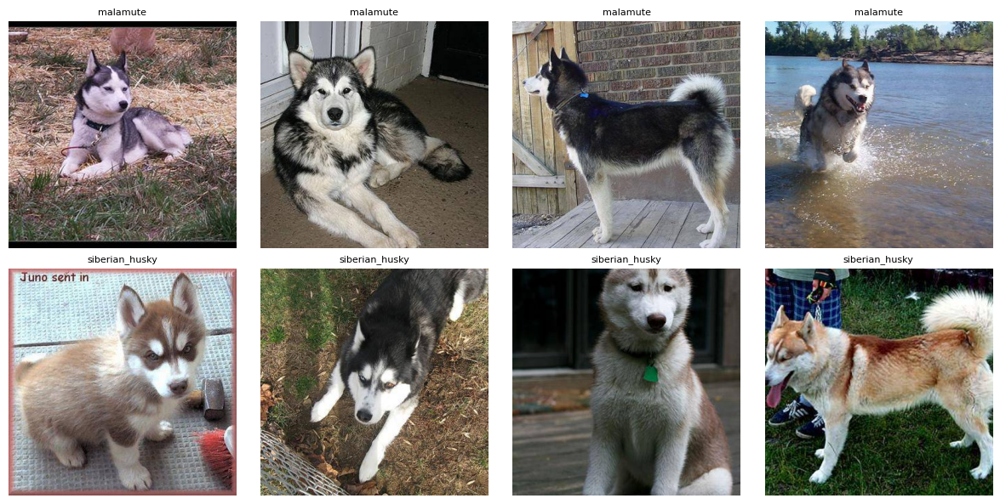

In [39]:
wrong = np.where(pred != y_va)[0]
worst_err = wrong[np.argsort(-P_VAL_FINAL[wrong, pred[wrong]])][:12]
show_images([cache[va_idx[i]] for i in worst_err],
            [f"vraie : {BREEDS[y_va[i]]} ({P_VAL_FINAL[i, y_va[i]]:.2f})\nprédite : {BREEDS[pred[i]]} ({P_VAL_FINAL[i, pred[i]]:.2f})"
             for i in worst_err], ncols=4, size=3.6)

A_, B_ = pairs.loc[0, "race A"], pairs.loc[0, "race B"]
ia = tr_idx[y_tr == BREED2IDX[A_]][:4]; ib = tr_idx[y_tr == BREED2IDX[B_]][:4]
show_images([cache[i] for i in ia] + [cache[i] for i in ib], [A_] * len(ia) + [B_] * len(ib), ncols=4, size=3)

### Interprétation des erreurs

- **Races « sœurs »** : le modèle final fait 710 erreurs sur 2 045 images. Les paires les plus confondues sont **malamute / siberian_husky** (11 confusions), **redbone / rhodesian_ridgeback** (9), **eskimo_dog / siberian_husky**, **norfolk / norwich terrier** et **irish_wolfhound / scottish_deerhound** (8 chacune), puis lhasa / shih-tzu, miniature / toy poodle, collie / shetland_sheepdog et doberman / miniature_pinscher (7). Le trio des chiens de traîneau (husky, malamute, eskimo dog) apparaît trois fois dans les 15 premières paires. La plupart des confusions sont **symétriques** (5 ↔ 6, 4 ↔ 4).
- **Spécificité AlexNet** : ses filtres larges et son sous-échantillonnage précoce captent bien les couleurs et les formes globales, mal les textures fines. Les races qui ne diffèrent que par la texture du pelage ou la forme des oreilles sont donc les plus touchées ; les races à couleur ou silhouette très distinctive (dalmatien, saint-bernard…) sont les plus faciles (graphique « races les plus faciles »).
- **Information absente** : la taille réelle du chien n'est pas visible sans repère d'échelle. C'est le critère principal entre toy et miniature poodle, entre doberman et miniature_pinscher (même robe noir et feu, tailles très différentes) et entre collie et shetland_sheepdog (le « sheltie » est presque un collie miniature). Ces confusions sont souvent **asymétriques** (6 ↔ 1) : le modèle prédit plutôt la race la plus représentée ou la plus « typique ».
- **Bruit des images** : parmi les erreurs les plus confiantes, chiens petits ou partiellement visibles, chiots, plusieurs chiens, étiquettes douteuses.
- **Pour la log loss** : les 5 % d'images les plus mal prédites représentent **21 %** de la log loss totale, d'où l'importance de la calibration et de l'ensemble, qui évitent les probabilités extrêmes sur ces images.

# 13. Prédictions sur le test et soumissions 2 et 3

- **Soumission 2** : configuration finale, entraînée sur 80 % du train (protocole validé).
- **Soumission 3** : même recette (hyperparamètres, nombre d'époques, températures, poids de l'ensemble) **réentraînée sur 100 % de `train/`**. Le fine-tuning est relancé sans validation pour exactement le nombre d'époques retenu (~5 min).
- `submission.csv` = soumission 3.

In [40]:
FINAL = json.load(open(os.path.join(WORK_DIR, "final_config.json")))
FT_CFGS = {"FT_CFG": FT_CFG, "FT_CFG2": FT_CFG2}
ALL_TRAIN = np.arange(N_TRAIN)

def member_test_probs(m, full):
    """Probabilités test d'un membre de l'ensemble ; full=True : réentraîné sur 100 % du train (même nombre d'époques)."""
    idx = ALL_TRAIN if full else tr_idx
    if m["kind"] == "head":
        f, ff = load_feats(m["layer"], m["res"])
        X, Y = np.asarray(f[idx]), y_all[idx]
        if m["flip"]:
            X, Y = np.concatenate([X, np.asarray(ff[idx])]), np.concatenate([Y, Y])
        head = (train_head(X, Y, stop_at=m["epoch"], **m["cfg"]) if full
                else train_head(X, Y, f[va_idx], y_va, **m["cfg"]))[0]
        lt = predict_logits(head, f[te_idx])
        if m["flip"]:
            lt = (lt + predict_logits(head, ff[te_idx])) / 2
    elif m["kind"] == "mv":
        key = (m["layer"], m["res"])
        if full:
            head = mv_fit(m["layer"], m["res"], m["cfg"], idx=ALL_TRAIN, stop_at=m["epoch"])[0]
        else:
            head = MV_HEADS[key] if key in MV_HEADS else mv_fit(m["layer"], m["res"], m["cfg"])[0]
        lt = mv_predict(head, m["layer"], m["res"], te_idx)
    else:                                                          # fine-tuning (résultats sauvegardés sur Drive)
        cfg, tag = FT_CFGS[m["cfg_name"]], f"{m['strategy']}_r{m['res']}"
        if not full:
            init = lp_head(m["res"], tr_idx)[0] if m["head_init"] == "lp" else None
            arrs = finetune(tag, cfg, tr_idx, init, m["train_convs"], res=m["res"])[1]
        else:
            init = None
            if m["head_init"] == "lp":
                _, lp_ep = lp_head(m["res"], tr_idx)
                init = lp_head(m["res"], ALL_TRAIN, stop_at=lp_ep)[0]
            arrs = finetune(tag + "_full100", cfg, ALL_TRAIN, init, m["train_convs"],
                            with_val=False, fixed_epochs=m["epoch"], res=m["res"])[1]
        lt = tta(arrs, "test", TTA_SETS[m["tta"]])
    return softmax(lt / m["T"], 1)

# Soumission 2 : modèles entraînés sur 80 %
P_TEST_80 = sum(m["w"] * member_test_probs(m, full=False) for m in FINAL["members"])
sub2 = write_submission(P_TEST_80, "submission_2_final_80pct.csv", download=True)

[S5_r224] résultats rechargés depuis Drive
[FT2_r288] résultats rechargés depuis Drive
OK : /content/drive/MyDrive/dog_breed_arena_alexnet/submissions/submission_2_final_80pct.csv — 10357 lignes x 121 colonnes, chaque ligne somme à 1


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [41]:
# Soumission 3 : même recette sur 100 % du train (le fine-tuning régularisé est relancé : ≈ 8-12 min)
P_TEST_FULL = sum(m["w"] * member_test_probs(m, full=True) for m in FINAL["members"])
sub3 = write_submission(P_TEST_FULL, "submission_3_final_100pct.csv", download=True)

print(f"Accord des prédictions 80 % vs 100 % : {(P_TEST_80.argmax(1) == P_TEST_FULL.argmax(1)).mean() * 100:.1f} %")
print(f"Confiance moyenne : 80 % = {P_TEST_80.max(1).mean():.3f} | 100 % = {P_TEST_FULL.max(1).mean():.3f}")

sub3.to_csv(os.path.join(SUB_DIR, "submission.csv"), index=False)
sub3.to_csv("submission.csv", index=False)
chk = pd.read_csv("submission.csv")
assert list(chk.columns) == list(sample.columns) and len(chk) == len(sample)
assert np.allclose(chk.iloc[:, 1:].sum(1), 1, atol=1e-5)
print("submission.csv conforme :", chk.shape)

[S5_r224_full100] résultats rechargés depuis Drive
[FT2_r288_full100] résultats rechargés depuis Drive
OK : /content/drive/MyDrive/dog_breed_arena_alexnet/submissions/submission_3_final_100pct.csv — 10357 lignes x 121 colonnes, chaque ligne somme à 1


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Accord des prédictions 80 % vs 100 % : 85.7 %
Confiance moyenne : 80 % = 0.584 | 100 % = 0.594
submission.csv conforme : (10357, 121)


In [42]:
# Compression des soumissions (~20 Mo chacune) pour l'envoi sur Kaggle — aucune valeur modifiée
import zipfile
for name in ["submission_1_best_strategy.csv", "submission_2_final_80pct.csv", "submission_3_final_100pct.csv"]:
    src = os.path.join(SUB_DIR, name)
    with zipfile.ZipFile(src + ".zip", "w", compression=zipfile.ZIP_DEFLATED) as z:
        z.write(src, arcname=name)
    print(f"{name}: {os.path.getsize(src) / 1e6:.1f} Mo → {os.path.getsize(src + '.zip') / 1e6:.1f} Mo")

submission_1_best_strategy.csv: 27.8 Mo → 11.4 Mo
submission_2_final_80pct.csv: 27.8 Mo → 11.9 Mo
submission_3_final_100pct.csv: 27.8 Mo → 11.8 Mo


# 14. Score officiel Kaggle

| Soumission | Fichier | Contenu | Log loss validation | Score Kaggle |
|---|---|---|---|---|
| 1 | `submission_1_best_strategy.csv` | AlexNet gelé, tête fc7 seule (S4) | 1,528 | **1,54519** |
| 2 | `submission_2_final_80pct.csv` | ensemble de 6 variantes d'AlexNet, entraîné sur 80 % | 1,233 | **1,22961** |
| 3 | `submission_3_final_100pct.csv` | même ensemble, réentraîné sur 100 % du train | — | **1,18027** |

![Score Kaggle](attachment:score_kaggle.png)

**Lecture des scores**

- **Notre validation est fiable** : les scores Kaggle sont très proches des log loss de validation (1,545 contre 1,528 ; 1,230 contre 1,233). Le jeu de validation stratifié reflète bien le jeu de test, et nos choix d'optimisation se transfèrent au test sans sur-ajustement.
- **L'optimisation fonctionne** : de la soumission 1 à la 2, la log loss baisse de **0,316** (−20 %). C'est le gain cumulé de la résolution, de la TTA 10 crops, du multi-vues, du fine-tuning régularisé et de l'ensemble pondéré.
- **Réentraîner sur 100 % du train est utile** : de la 2 à la 3, la log loss baisse encore de **0,049**. Avec ~68 images par race, 25 % d'images en plus (~17 par race) améliorent nettement le modèle. Réutiliser les hyperparamètres et le nombre d'époques choisis en validation suffit ; la soumission 3 est notre soumission officielle (`submission.csv`).
- **Repère** : une prédiction au hasard donne ln(120) ≈ 4,79 ; notre modèle final est environ 4 fois meilleur.

In [43]:
# La capture du score est intégrée dans la cellule de texte ci-dessus.
print("Scores Kaggle : soumission 1 = 1.54519 | soumission 2 = 1.22961 | soumission 3 = 1.18027")

Scores Kaggle : soumission 1 = 1.54519 | soumission 2 = 1.22961 | soumission 3 = 1.18027


# 15. Chiffres clés pour les réponses et la conclusion

In [44]:
print(f"AlexNet : {TOTAL_PARAMS / 1e6:.1f} M paramètres, dont {fc_p / TOTAL_PARAMS * 100:.0f} % dans fc6-fc8 "
      f"(fc6 seule : {9216 * 4096 / 1e6:.1f} M)")
print(f"Hasard : log loss = ln(120) = {np.log(120):.3f}")
for _, r in bench.iterrows():
    print(f"  {r['Code']} {r['Stratégie']:42s} logloss {r['Log Loss val']:.4f} | acc {r['Accuracy val']:.4f}")
gains = exp_df.dropna(subset=["Δ vs meilleur précédent"])
g = gains.loc[gains["Δ vs meilleur précédent"].idxmin()]
print(f"Plus grand gain de l'optimisation : [{g['étape']}] {g['description']} (Δ = {g['Δ vs meilleur précédent']:+.4f})")
final_ll = float(-np.log(P_VAL_FINAL[np.arange(len(y_va)), y_va] + 1e-15).mean())
print(f"Log loss : meilleure stratégie du benchmark {bench['Log Loss val'].min():.4f} → modèle final {final_ll:.4f} "
      f"(fc7 de base : {nll(VAL_BENCH['S4'], y_va):.4f})")
sp = {k: v for k, v in SPEED.items() if k.endswith(f"_r{NATIVE_RES}")}
display(pd.DataFrame(sp).T.assign(**{"taille fp32 (Mo)": lambda d: d["params"] * 4 / 1e6,
                                     "taille int8 (Mo)": lambda d: d["params"] / 1e6}))

AlexNet : 61.1 M paramètres, dont 96 % dans fc6-fc8 (fc6 seule : 37.7 M)
Hasard : log loss = ln(120) = 4.787
  S6 fine-tuning complet — aucun gain (époque 0) logloss 1.5279 | acc 0.5785
  S5 fine-tuning partiel (convolutions gelées) — aucun gain (époque 0) logloss 1.5279 | acc 0.5785
  S4 extraction fc7 (4096)                      logloss 1.5279 | acc 0.5790
  S3 extraction fc6 (4096)                      logloss 1.5532 | acc 0.5716
  S1 extraction pool5 + pooling global (256)    logloss 1.7700 | acc 0.5164
  S2 extraction pool5 aplatie (9216)            logloss 2.1761 | acc 0.4650
Plus grand gain de l'optimisation : [C1] ensemble pondéré de 6 modèles (poids et températures en validation croisée) (Δ = -0.1199)
Log loss : meilleure stratégie du benchmark 1.5279 → modèle final 1.2331 (fc7 de base : 1.5279)


,params,ms_gpu_batch_fp16,ms_gpu_bs1_fp32,ms_cpu_bs1,taille fp32 (Mo),taille int8 (Mo)
pool5_gap_r224,2.5005e+06,0.1148,1.3797,13.6884,10.0021,2.5005
pool5_r224,3.5757e+06,0.1198,1.3820,38.3057,14.3029,3.5757
fc6_r224,4.0714e+07,0.1279,2.2215,25.9362,162.8567,40.7142
fc7_r224,5.7495e+07,0.1340,2.4450,31.2141,229.9819,57.4955


# 16. Réponses aux questions

**1. Pourquoi un modèle pré-entraîné sur ImageNet est-il particulièrement efficace sur ce problème ?**
Un CNN entraîné sur 1,28 M d'images apprend une hiérarchie de détecteurs : contours et couleurs en `conv1` (visibles sur nos filtres), textures et motifs au milieu, parties d'objets dans `conv5` et combinaisons abstraites dans `fc6`/`fc7`. Ces détecteurs se réutilisent sur d'autres photos. Ici, les 120 races font même partie des 1 000 classes d'ImageNet : même AlexNet, un réseau de 2012, atteint ~58 % d'accuracy avec une simple régression logistique sur ses features gelées, alors que le hasard donne 0,8 %. Entraîner ses 61 M de paramètres de zéro avec ~68 images par race serait impossible.

**2. Différence entre extraction de features et fine-tuning ? Laquelle avez-vous choisie et pourquoi ?**
*Extraction* : le réseau est gelé, on calcule une fois la représentation d'une couche et on entraîne seulement un classifieur dessus (S1–S4). *Fine-tuning* : on continue l'entraînement des poids pré-entraînés avec un petit taux d'apprentissage (S5 partiel, S6 complet).
Nous avons **mesuré les deux** sur le même protocole (section 10). Le fine-tuning « naïf » (fc8 initialisée par la tête logistique, taux 1e-4) n'a **rien apporté** : la loss d'entraînement tombe à ≈ 0,10 dès la 1re époque pendant que celle de validation monte — les ~55 M de paramètres de `fc6`/`fc7` mémorisent les 8 177 images. Nous avons donc gardé l'**extraction de features** comme socle (rapide, ≈ 1,43 avec la bonne couche et la bonne résolution), puis proposé un fine-tuning **régularisé** (mixup, recadrages forts, taux 3e-5, fc8 aléatoire) qui atteint 1,3786 (meilleur modèle seul) et reçoit le plus grand poids (0,29) de l'ensemble final. Leçon : avec peu d'images par classe et un réseau dont 96 % des paramètres sont dans des couches denses, le fine-tuning exige une régularisation forte.

**3. Pourquoi VGG16 possède-t-il beaucoup plus de paramètres que ResNet50 alors qu'il est moins profond ?**
Pour la même raison qu'AlexNet, que nous avons mesurée (section 6) : les paramètres sont dans les **couches entièrement connectées**. Une couche dense relie chaque entrée à chaque sortie : `fc6` d'AlexNet relie 9 216 valeurs à 4 096 neurones, soit ~38 M de poids, plus que les 5 convolutions réunies (~2,5 M). VGG16 a le même bloc final (7×7×512 = 25 088 → 4 096 → 4 096 → 1 000, ≈ 124 M sur 138 M). ResNet50 remplace ce bloc par un *global average pooling* suivi d'une seule couche 2 048 → 1 000 (~2 M) et utilise des convolutions 1×1 de réduction : 25,6 M paramètres pour 50 couches. Le nombre de paramètres dépend de la largeur des couches et du classifieur, pas de la profondeur.

**4. Que permettent les connexions résiduelles de ResNet ? Et les convolutions séparables de MobileNetV2 ?**
- *Connexions résiduelles* : chaque bloc calcule `y = F(x) + x` ; il n'apprend qu'une correction, et le chemin identité laisse passer le gradient jusqu'aux premières couches. Cela permet d'entraîner 50 à 150 couches. AlexNet n'en a pas : c'est une des raisons pour lesquelles il est limité à 8 couches, donc à des features peu abstraites.
- *Convolutions séparables en profondeur* : une convolution 3×3 classique est remplacée par une convolution 3×3 par canal puis une convolution 1×1 qui mélange les canaux ; le coût passe de `9·Cin·Cout` à `9·Cin + Cin·Cout`, soit ~8-9 fois moins de calculs. AlexNet utilise des convolutions classiques avec de grands noyaux (11×11, 5×5), ce qui le rend lourd pour sa précision.

**5. Le classement est-il le même selon l'Accuracy et selon la Log Loss ?**
Voir le tableau des rangs (section 10). L'accuracy ne regarde que la classe la plus probable ; la log loss regarde la probabilité donnée à la vraie classe. Un modèle sur-confiant (0,99 sur la mauvaise race → perte −ln(0,01) ≈ 4,6 pour une seule image) est lourdement pénalisé. Les colonnes « Confiance moyenne », « ECE » et l'effet de la température (qui change la log loss **sans** changer l'accuracy) expliquent les éventuelles inversions.

**6. Comment avez-vous détecté et limité l'overfitting ?**
*Détection* : validation fixe et stratifiée ; courbes de loss entraînement vs validation pour chaque stratégie : la loss d'entraînement continue de baisser quand celle de validation remonte. *Limitation* : early stopping (époque du minimum de validation), dropout sur les features et weight decay (grille A2), augmentation par miroir pour les têtes, augmentation de données complète et dropout 0,5 d'origine d'AlexNet pour le fine-tuning, taux d'apprentissage faibles, calibration et validation croisée des réglages.

**7. Quelle amélioration a eu le plus d'impact sur votre score, et pourquoi ?**
D'après la cellule « plus grand gain » (section 15), c'est l'**ensemble pondéré** (−0,120), devant la **TTA 10 crops** (−0,082 sur la piste B), la **résolution 352 px** (−0,065) et l'**entraînement multi-vues** (−0,025). Au total, la log loss passe de 1,528 (tête `fc7` simple) à 1,233 (modèle final), et l'accuracy de 57,9 % à 65,3 %. Explication : la limite d'AlexNet est double — des features qui perdent les détails fins (corrigé par la résolution et les crops) et une forte tendance à mémoriser (corrigée par le multi-vues, le mixup et l'ensemble). L'ensemble gagne le plus parce que des modèles à résolutions et couches différentes ne font qu'en partie les mêmes erreurs (corrélation des erreurs ≈ 0,6) : la moyenne corrige une partie des erreurs et surtout adoucit les probabilités sur les images ambiguës.

### Questions probables sur AlexNet

**8. Quelles sont les innovations d'AlexNet en 2012 ?** ReLU (gradient non saturé, entraînement ~6 fois plus rapide que tanh), dropout (réduit l'overfitting des énormes couches denses), augmentation de données (crops aléatoires, miroirs, variations de couleur), max-pooling chevauchant, entraînement sur 2 GPU. La normalisation LRN de l'original n'existe pas dans la version torchvision.

**9. Pourquoi un premier filtre 11×11 de pas 4, et quel effet sur notre problème ?** Pour réduire très vite la taille de l'image (224 → 55) et rendre l'entraînement possible sur les GPU de 2012. Le prix : les détails fins sont perdus dès la première couche. Notre étude de résolution (A3) le mesure directement : passer de 224 à 352 px améliore la log loss de `fc6` de ≈ 1,488 à ≈ 1,423. Les réseaux suivants (VGG, ResNet) utilisent des filtres 3×3 empilés.

**10. Pourquoi utiliser la normalisation du pré-entraînement ?** Les poids de `conv1` ont été appris sur des entrées centrées-réduites avec cette moyenne et cet écart-type précis ; une autre normalisation décale toutes les activations et dégrade les features. Nous lisons ces valeurs dans les métadonnées des poids.

**11. Pourquoi `fc6` peut-elle donner de meilleures features que `fc7` ?** Plus une couche est haute, plus elle est spécialisée vers la tâche d'origine (les 1 000 classes d'ImageNet). `fc6` est plus générique ; `fc7` est déjà très orientée vers la décision finale. Comparez S3 et S4.

**12. Pourquoi l'augmentation de données est-elle utile pour le fine-tuning et pas pour l'extraction ?** Avec un réseau gelé et des features pré-calculées, chaque image ne donne qu'un seul vecteur : il faudrait recalculer les features pour chaque augmentation (nous l'avons fait seulement pour le miroir). En fine-tuning, chaque époque voit des versions différentes des images, ce qui empêche de mémoriser le train.

# 17. Conclusion

### Résultat final

| | Log loss | Accuracy |
|---|---|---|
| Hasard (1/120 partout) | 4,787 | 0,8 % |
| AlexNet de base (tête `fc7`), validation | 1,528 | 57,9 % |
| Modèle final (ensemble de 6 variantes d'AlexNet), validation | 1,233 | 65,3 % |
| **Score Kaggle officiel (soumission 3)** | **1,18027** | — |

En partant d'AlexNet seul, nous avons fait passer le score Kaggle de **1,545 à 1,180**, soit **−24 %**, et notre modèle final est environ **4 fois meilleur que le hasard**. Les scores Kaggle sont très proches de nos scores de validation (1,545 contre 1,528 ; 1,230 contre 1,233) : notre protocole d'évaluation est fiable.

### Ce que nous avons appris

1. **Le transfer learning est indispensable.** Avec ~85 images par race, entraîner AlexNet de zéro est impossible ; réutilisé après pré-entraînement sur ImageNet, une simple régression logistique sur ses features atteint déjà 57,9 % d'accuracy.
2. **Le choix de la couche compte.** `fc7` et `fc6` sont les meilleures couches ; `pool5` aplatie (9 216 dimensions) est la pire, car elle sur-apprend.
3. **Le point faible d'AlexNet est le filtre 11×11 de pas 4.** Agrandir les images à 352 px (−0,065) et la TTA 10 crops (−0,082) compensent en partie la perte des détails fins.
4. **Le vrai problème est la mémorisation.** Le fine-tuning naïf n'a rien apporté (la loss d'entraînement tombait à 0,10 dès la 1re époque). L'entraînement multi-vues et le fine-tuning régularisé avec mixup ont corrigé ce problème.
5. **L'ensemble est l'amélioration la plus efficace** (−0,12) : 6 variantes d'AlexNet (couches, résolutions, entraînements différents) font des erreurs en partie différentes, et leur moyenne les corrige.
6. **Réentraîner sur 100 % du train est utile** : 1,230 → 1,180 sur Kaggle, grâce à 25 % d'images en plus.
7. **Limites restantes** : les races très proches (malamute / husky, caniches, collie / sheltie) restent confondues, surtout quand la taille du chien, invisible sur la photo, est le critère principal.

### Recommandations de déploiement

**Serveur.** AlexNet est très rapide sur GPU : ≈ 2,4 ms par image seule et ≈ 0,13 ms par image par lot (≈ 7 500 images/s sur un T4). Notre modèle final complet (ensemble + vues multiples) reste à quelques millisecondes par image : il convient à un service à fort volume et à faible coût. Si la précision est la priorité absolue, un réseau plus récent ferait mieux : la limite d'AlexNet est la qualité de ses features, pas sa vitesse.

**Mobile.** AlexNet est peu adapté : 57 M paramètres (≈ 230 Mo en float32, ≈ 58 Mo en int8), dont 96 % dans les couches denses, et ≈ 31 ms par image sur CPU. Deux options issues de nos mesures :
- la variante légère S1 (`pool5` + pooling global) : 2,5 M paramètres (≈ 10 Mo), ≈ 14 ms sur CPU, mais une log loss plus élevée (1,77) ;
- une seule tête `fc6` quantifiée en int8, sans l'ensemble, pour un compromis taille / précision.

### Pistes d'amélioration

Recadrage centré sur le chien (détection préalable), cutmix, davantage de vues aléatoires pour le multi-vues, et distillation de l'ensemble vers la variante légère S1 pour le mobile.